# Simulation and segmentation of DNA imaged by AFM

<a href="https://colab.research.google.com/github/Prakhar-Dutta/ASAP/blob/main/tutorials/dna-imaging/segmentation/DNA_simulation_and_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> **On Colab Python 3.12.13, run section 0 first.** It installs the pinned TopoStats contour profile and downloads the helpers, checkpoints, presets and example assets. Every function and the benchmark memory tracker are in the helper files; the dataset, loss, metric and network classes stay in this notebook.

**This notebook simulates closed DNA molecules (plasmids and minicircles) relaxing on a substrate, renders them as atomic force microscopy (AFM) height images, and trains or loads a U-Net that segments the DNA and its crossings in simulated and real AFM data.**

It has two parts:

1. **Dataset generation.** Each sample is a simulated AFM height map (`.npy`, heights in nm, with realistic noise from a blank `.spm` scan or a PSD noise model), a binary **DNA mask** and a soft **crossing mask** that highlights where the molecule crosses itself. Metadata for every sample (seed, contour length, bead count, rendering parameters) is saved and indexed in a central `manifest.csv`.
2. **Segmentation.** A two-headed U-Net (DNA + crossings), built with [Deeplay](https://github.com/DeepTrackAI/deeplay) and fed by a lazy [DeepTrack](https://github.com/DeepTrackAI/DeepTrack2) pipeline, is trained on the simulated data, or one of the provided trained networks is loaded. It is evaluated on simulated data and then applied to real AFM data. Real `.spm` scans are analysed with [TopoStats](https://github.com/AFM-SPM/TopoStats) using the U-Net for segmentation.

The chains can be made **with molecular dynamics** (OpenMM, more realistic, about 15 s per molecule on a GPU) or **without** (a calibrated 2-D ring generator, about 2 s per molecule, no OpenMM needed). All default values are the optimised settings that produced the training data of the provided networks.

---

**Where the code is.** To keep the notebook readable, every function lives in a helper script next to this notebook. Class definitions (dataset, loss, metrics, networks) are written out in the notebook.

| File / folder | Contents |
|---|---|
| `dna_simulation_helpers.py` | all functions used in Part 1: chain generation (MD and non-MD), MD relaxation, AFM rendering, noise, masks, crossings, decoys, sanity check, benchmark, dataset generation |
| `unet_segmentation_helpers.py` | all functions used in Part 2: manifest → DeepTrack sources, lazy loading, loss building blocks, checkpoints, metrics, previews, real-data evaluation, TopoStats |
| `checkpoints/` | trained networks: `md_res_unet.pt`, `md_simple_unet.pt`, `non_md_res_unet.pt`, `non_md_simple_unet.pt` |
| `configs/` | TopoStats settings for relaxed plasmids, supercoiled plasmids and minicircles |
| `../common-assets/` | blank-scan noise and PSD noise model, real example images and scan, real test images with masks |

**Cell execution order.**

| I want to… | Run |
|---|---|
| run on Colab or Kaggle | section **0** first, then as below |
| generate a dataset only | Part 1, sections **1 → 8**, top to bottom |
| segment only (pre-trained networks, a dataset made earlier, or my own data) | the **imports cell in section 1**, then Part 2, sections **9 → 15** |
| both | the whole notebook, top to bottom |

Sections 2-7 (chain schematic, OpenMM test, relaxation, real examples, sanity check, benchmark) are optional checks; dataset generation (section 8) only needs sections 1.1-1.3.

## 0. Running on Colab or Kaggle

Run this setup cell first on the standard **Python 3.12.13 Colab runtime**. It downloads the helpers, four checkpoints, your fine-tuned YAML presets, the small shared noise assets and an example scan; it installs Deeplay, DeepTrack, OpenMM and the **ASAP contour profile of TopoStats 2.4.2**. No Git clone or Python downgrade is needed. Set `INSTALL_TOPOSTATS = False` if you only need simulation or image segmentation without raw `.spm` analysis.

The official TopoStats release excludes Python 3.12 because of its `topoly` dependency. `setup_topostats.py` verifies the small official PyPI wheel's SHA-256 and builds `2.4.2+asap312.1`: scan processing, crossing resolution, ordered traces, circularity and contour lengths are retained; **Jones-polynomial knot/link classification is omitted**, and uncomputed classification is `None`. This is an explicitly modified build, not an official Python 3.12 release. Its source changes and license are documented in [TOPOSTATS_PYTHON312.md](TOPOSTATS_PYTHON312.md).

Use a fresh session. If installation changes NumPy or TensorFlow that you already imported, restart the session once and rerun this cell before continuing. On Kaggle enable Internet. Locally, install `requirements.txt` and run `python setup_topostats.py` in your Python 3.10–3.12 environment.


In [1]:
# Only needed on Colab or Kaggle; use a fresh runtime before importing numerical libraries.
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

ON_COLAB = "google.colab" in sys.modules
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
INSTALL_TOPOSTATS = True        # raw .spm analysis in section 15
REFRESH_HELPERS = True          # refresh code; keep existing checkpoints and data
REPOSITORY_REF = "main"         # can be pinned to a reviewed commit after publication
DNA_URL = f"https://raw.githubusercontent.com/Prakhar-Dutta/ASAP/{REPOSITORY_REF}/tutorials/dna-imaging/"
HELPERS = ["dna_simulation_helpers.py", "unet_segmentation_helpers.py", "setup_topostats.py"]
NOTEBOOK_FILES = HELPERS + [
    "checkpoints/md_res_unet.pt", "checkpoints/md_simple_unet.pt",
    "checkpoints/non_md_res_unet.pt", "checkpoints/non_md_simple_unet.pt",
    "configs/topostats_relaxed.yaml", "configs/topostats_supercoiled.yaml",
    "configs/topostats_minicircle.yaml",
]
SHARED_FILES = [
    "noise/20240411_blank_water.0_00000.spm", "noise/psd_noise_model.npz",
    "example-spm/20240513_rel_PJIP37_unknot_4ng_eph_ni__.0_00090.spm",
]

if ON_COLAB or ON_KAGGLE:
    for name in NOTEBOOK_FILES:
        destination = Path(name)
        if not destination.exists() or (REFRESH_HELPERS and name in HELPERS):
            destination.parent.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(DNA_URL + "segmentation/" + name, destination)
            print("Downloaded", name)
    for name in SHARED_FILES:
        destination = Path("../common-assets") / name
        if not destination.exists():
            destination.parent.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(DNA_URL + "common-assets/" + name, destination)
            print("Downloaded", name)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "deeplay==0.1.4", "deeptrack==2.0.1", "openmm[cuda12]", "psutil", "joblib"], check=True)
    if INSTALL_TOPOSTATS:
        subprocess.run([sys.executable, "setup_topostats.py"], check=True)
    print("Setup finished. If already-imported numerical libraries changed, restart once and rerun setup.")
else:
    print("Local environment: use requirements.txt and python setup_topostats.py.")


Local environment: use requirements.txt and python setup_topostats.py.


# Part 1 — Dataset generation

## 1. Setting up the simulation

### 1.1 Imports, and with or without molecular dynamics?

Simulated DNA chains can be built in two ways:

* **With coarse-grained molecular dynamics (`USE_MD = True`).** A closed chain of beads starts as a 3-D random walk above the substrate and is relaxed onto it with [OpenMM](https://openmm.org) (bonds, bending stiffness, surface attraction, height confinement and excluded volume). This is slower but produces the most realistic conformations and crossings. OpenMM uses a GPU when it can (CUDA or OpenCL) and otherwise the CPU.
* **Without molecular dynamics (`USE_MD = False`).** A calibrated 2-D persistent ring is drawn directly on the substrate. It is much faster and needs no OpenMM, at the cost of less realistic crossings.

This cell imports everything Part 1 needs (including what the benchmark and dataset generation use) and loads OpenMM only for the MD pathway. **If you only want to run Part 2, run this cell first.**

In [2]:
# ── Part 1 imports ───────────────────────────────────────────────────────────
from __future__ import annotations   # lets the classes refer to themselves in type hints

import os
import threading
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import psutil

import dna_simulation_helpers as sim   # all Part 1 functions

# ── Chain generation pathway ─────────────────────────────────────────────────
USE_MD = True   # True  → OpenMM molecular dynamics (realistic, ~15 s per molecule)
                # False → calibrated 2-D persistent ring (fast, ~2 s per molecule, no OpenMM)

if USE_MD:
    # In a fresh environment, install OpenMM first (choose the CUDA build that matches
    # your system, or plain `openmm` for CPU/OpenCL):
    # !pip install openmm[cuda12]
    import openmm
    import openmm.unit as unit

    platforms = [openmm.Platform.getPlatform(i).getName() for i in range(openmm.Platform.getNumPlatforms())]
    print("OpenMM", openmm.__version__, "| available platforms:", platforms)
else:
    print("Non-MD pathway selected: OpenMM is not needed.")

OpenMM 8.6.1 | available platforms: ['Reference', 'CPU', 'OpenCL']


### 1.2 Defining the variables

These variables control how the simulated molecules and images look. They are grouped as follows:

* **Dataset**: where the data is written, how many samples, and the first random seed.
* **Image**: image size and pixel size, the DNA **contour length**, the internal rendering resolution and the AFM tip radius.
* **Chain**: bead-level settings shared by both pathways (their optimised values differ per pathway, so both are listed).
* **MD pathway** and **Non-MD pathway**: settings used by only one pathway.
* **Fine-tuning**: everything else (rendering, masks, crossings, decoys). These are the optimised values; change them only if you know why.

**Contour length.** The contour length is the length of the DNA backbone, the most natural way to describe a molecule (1 bp ≈ 0.34 nm, so the default 768.4 nm is a 2.26 kbp plasmid and 115.26 nm a 339 bp minicircle). Internally the closed chain is made of beads joined by bonds, so its length is *number of beads × bond length*. The notebook picks the number of beads as `CONTOUR_LENGTH_NM / BOND_LENGTH`, rounded, and then stretches the bond slightly so that the product equals the requested contour length. Asking for 1 nm more therefore gives a molecule about 1 nm longer: exactly for the non-MD pathway, and within thermal fluctuations of the bonds (typically below 0.5 %) for the MD pathway.

The field of view is `NX × NM_PER_PIXEL` by `NY × NM_PER_PIXEL` nm. Molecules are centred in it and are never cropped: a molecule that does not fit is rejected and the next seed is used. The defaults (512 px at 1 nm per pixel) fit the 768.4 nm plasmids.

The last line hands the variables to the helper script (`sim.configure(globals())`). Re-run this cell after changing any of them.

In [3]:
# ═══════════════════════ Dataset ═══════════════════════
OUT_DIR = "dna_dataset_md" if USE_MD else "dna_dataset_non_md"   # output folder
N_SAMPLES = 1    # number of samples to generate
BASE_SEED = 1         # seed of the first sample; every attempt uses the next seed

# ═══════════════════════ Image ═══════════════════════
NX, NY = 512, 512            # image size (pixels)
NM_PER_PIXEL = 1.0           # pixel size (nm) → 511 nm field of view
CONTOUR_LENGTH_NM = 768.4    # DNA contour length (nm) used for single molecules (sections 2-4, benchmark)
CHAIN_RESOLUTION_NM = 0.5    # internal rendering grid (nm per pixel); smaller is finer but slower
TIP_RADIUS_NM = 7.0 if USE_MD else 8.662717273203071   # AFM tip radius (nm)

# ═══════════════════════ Chain (both pathways) ═══════════════════════
# These describe the chain bead by bead and are therefore linked to the contour length:
#   number of beads = CONTOUR_LENGTH_NM / BOND_LENGTH (rounded; the bond is then adjusted so that
#   beads × bond = CONTOUR_LENGTH_NM). Changing BOND_LENGTH changes the number of beads, and because
#   PERSISTENCE_BONDS and K_ANGLE act per bond, changing any of the three changes how stiff the chain is
#   in nm (persistence ≈ PERSISTENCE_BONDS × BOND_LENGTH) and hence its shape. The requested contour
#   length itself is kept.
if USE_MD:
    BOND_LENGTH = 4.5            # preferred distance between neighbouring beads (nm)
    PERSISTENCE_BONDS = 40.0     # directional memory of the initial random walk (in bonds)
    K_ANGLE = 15                 # bending stiffness of the MD force field (in kT)
else:
    BOND_LENGTH = 7.362098159496696
    PERSISTENCE_BONDS = 8.395369256503411
    K_ANGLE = 15                 # MD only; the non-MD ring uses ANGLE_STIFFNESS_MULT below

# ═══════════════════════ MD pathway ═══════════════════════
BASE_Z = 55.0            # height (nm) of the initial ring above the substrate before relaxation
N_FRAMES = 350           # number of recorded MD frames
STEPS_PER_FRAME = 300    # integration steps between frames (350 × 300 = 105,000 steps)

# ═══════════════════════ Non-MD pathway ═══════════════════════
ANGLE_STIFFNESS_MULT = 1.3329571644033593   # larger → less turning per bond → smoother ring

# ═══════════════════════ Fine-tuning (optimised values) ═══════════════════════
DNA_HEIGHT_NM = 2.3 if USE_MD else 2.736565473663223   # rendered DNA height for single renders (nm)
DNA_MASK_DIAMETER_NM = 4.47        # DNA width in the training masks (nm), both pathways

# AFM renderer
if USE_MD:   # width/taper renderer of the MD training data
    AFM_KW = dict(dna_diameter_nm=4.47, taper_width_nm=2.2, taper_sigma_nm=2.7, taper_floor=0.05,
                  max_height_nm=5.0, final_blur_sigma_px=0.22, grain_nm=0.0, grain_sigma_px=0.6,
                  min_separation_beads=12, boost_window_beads=1, guaranteed_offset_nm=0.25,
                  boost_sigma_beads=0.4, far_clip_nm=2.5, far_clip_window_beads=3)
else:        # calibrated non-MD renderer (run 8 fit + crossing-height calibration)
    AFM_KW = dict(dna_diameter_nm=2.767728478821522, taper_width_nm=None, taper_sigma_nm=1.0450175443840577,
                  taper_floor=0.7455919906735349, max_height_nm=1e6,
                  final_blur_sigma_px=1.2602878701389546 * 0.5 / NM_PER_PIXEL,   # 0.63 nm physical blur
                  grain_nm=0.14555907215572678, grain_sigma_px=0.25,
                  min_separation_beads=10, boost_window_beads=2, guaranteed_offset_nm=0.2693638003135165,
                  boost_sigma_beads=3.379404216948316, far_clip_nm=5.556628432553081, far_clip_window_beads=14)
AFM_KW.update(nx=NX, ny=NY, dna_height_nm=DNA_HEIGHT_NM, tip_radius_nm=TIP_RADIUS_NM,
              chain_resolution_nm=CHAIN_RESOLUTION_NM, max_radius_px=128, radius_shrink_px=0.0,
              apply_edge_taper=True, add_center_ridge=False, ridge_sigma_nm=0.16, ridge_amp_nm=0.04,
              enable_crossing_boost=True, boost_method="absolute", boost_profile="gaussian",
              return_crossing_info=True, return_masks=True)

# Non-MD ring shape
NON_MD_ANGLE_LIMIT_RAD = 2.2072170954704875   # cap on the turning angle per bond
NON_MD_Z_STD_NM = 0.0                         # height scatter of the beads
NON_MD_BASE_Z_NM = 0.2                        # bead height above the substrate

# Crossing mask
CROSS_MIN_SEP_BEADS = 3              # minimum bead separation for two segments to count as a crossing
CROSS_SIGMA_CENTER_DIAM_MULT = 1.0   # crossing blob size along the strand (× mask diameter)
CROSS_SIGMA_PERP_DIAM_MULT = 0.5     # crossing blob size across the strand (× mask diameter)
CROSS_CHAIN_EXTENT = 1.0             # beads on each side of a crossing included in the mask
CROSS_CENTER_WEIGHT = 0.75           # weight of the overlap region
CROSS_CHAIN_WEIGHT = 0.5             # weight of the crossing strands
CROSS_CLIP_TO_DNA_MASK = False       # clip the crossing mask to the DNA mask

# Decoy fragments (short pieces of DNA that are not part of the molecule)
DECOY_EVERY_N_SAMPLES = 50                     # every 50th sample gets a decoy (0 = never)
DECOY_N_BEADS_RANGE_POOL = [(2, 3), (3, 5), (4, 6)]

# ── hand the variables to the helper script ──────────────────────────────────
sim.configure(globals())
n_beads, bond = sim.contour_to_beads(CONTOUR_LENGTH_NM, BOND_LENGTH)
print(f"Pathway: {'MD' if USE_MD else 'non-MD'} | {CONTOUR_LENGTH_NM:g} nm → {n_beads} beads × {bond:.4f} nm "
      f"| field of view {(NX - 1) * NM_PER_PIXEL:.0f} × {(NY - 1) * NM_PER_PIXEL:.0f} nm | output: {os.path.abspath(OUT_DIR)}")

Pathway: MD | 768.4 nm → 171 beads × 4.4936 nm | field of view 511 × 511 nm | output: C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\dna_dataset_md


### 1.3 Noise

To add realistic noise to the images so that they closely resemble real AFM images, two options are provided.

1. For users with access to an AFM and substrates, a **blank `.spm`** scan can be used. A blank is a scan of the substrate **without** the sample of interest. The notebook parses the file, removes the plane tilt and line offsets as TopoStats would, and uses what remains as a noise texture, so the simulated data looks as if the DNA had been imaged on that set-up and substrate.
2. Without a blank, noise is generated from a **power spectral density (PSD) model** built from an ensemble of blanks imaged on nickel substrates. The model is in `../common-assets/noise/`. Three synthesis methods are offered; *mean_full2d* is preferred and is the default.

`TARGET_NOISE_RMS_NM` sets the noise amplitude (RMS height, nm) for single images; the dataset draws it from `NOISE_RMS_RANGE_NM` in section 8. The defaults match the optimised data of each pathway. The noise source is loaded at the end of this cell.

In [4]:
# Noise
TARGET_NOISE_RMS_NM = 0.10 if USE_MD else 0.16
# This variable controls the height of the noise in nanometers
# and this is added to the final image

# Blank SPM noise
USE_BLANK_SPM_NOISE = True
USE_PLANE_REMOVE = True
# This flag is used to control plane tilt removal from the noise image
USE_LINE_FLATTEN = True
# This flag is used to control line flattening (median filtering) from the noise image
USE_BANDPASS_FILTER = True
# This flag is used to control bandpass filtering on the noise image
BLANK_SPM_PATH = "../common-assets/noise/20240411_blank_water.0_00000.spm"
# optional; if missing/invalid, PSD fallback noise is used

# PSD-model fallback noise (used when blank .spm file is not available)
USE_PSD_NOISE_FALLBACK = True
MODEL_PATH = "../common-assets/noise/psd_noise_model.npz"
PSD_NOISE_METHOD = "mean_full2d"
# or "lognormal_full2d" / "empirical_radial"
PSD_NOISE_STD_SCALE = 2.0

sim.configure(globals())
noise_source, noise_asset, noise_diag = sim.load_noise_asset()

Chosen block: 'Z offset: V [Sens. DeformationSens] (0.00000000093132 V/LSB) 0.01733094 V' 512x512 bpp=4 decode=<i4
Robust p1=262, p99=9.96e+04, range=9.94e+04, var=7.89e+08
Loaded via parser: (512, 512) | units: as-is (nm or counts)
Extracted noise RMS (bg): 0.1000 nm | tex shape: (512, 512)
Loaded blank .spm noise texture  RMS ≈ 0.100 nm


## 2. Chain creation

Before relaxation, a chain is created bead by bead.

* **MD pathway.** A closed ring is built as a 3-D *persistent random walk*: each step turns the direction by a small random angle, with `PERSISTENCE_BONDS` setting how long the direction is remembered. The increments are made periodic so the ring closes on itself, the beads are respaced evenly along the curve, and the ring is lifted to `BASE_Z` above the substrate so that it can relax down onto it in the next step (`sim.make_tangled_ring_initial_safe`).
* **Non-MD pathway.** The ring is drawn directly in 2-D on the substrate with a smoothed, periodic sequence of turning angles and then scaled to the exact contour length (`sim.make_non_md_ring`).

The schematic shows the chain in 3-D with the substrate as a plane (z = 0) and bead 0 in red.

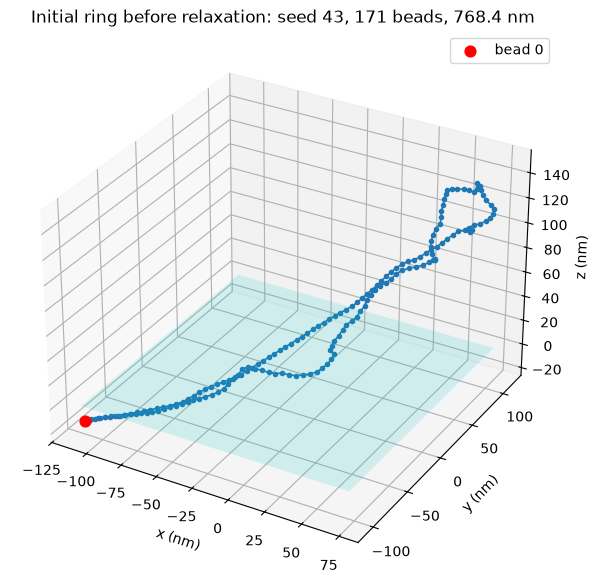

In [5]:
demo_seed = 43
n_beads, bond = sim.contour_to_beads(CONTOUR_LENGTH_NM, BOND_LENGTH)
if USE_MD:
    demo_coords = sim.make_tangled_ring_initial_safe(
        demo_seed, n_beads, bond, persistence_bonds=PERSISTENCE_BONDS, base_z=BASE_Z)
    title = f"Initial ring before relaxation: seed {demo_seed}, {n_beads} beads, {sim.closed_contour_nm(demo_coords, use_z=True):.1f} nm"
else:
    demo_coords = sim.make_non_md_ring(demo_seed, CONTOUR_LENGTH_NM)
    title = f"Non-MD ring: seed {demo_seed}, {n_beads} beads, {sim.closed_contour_nm(demo_coords):.1f} nm"

sim.plot_initial_chain(demo_coords, title)

## 3. Molecular dynamics relaxation

To mimic how DNA relaxes onto a substrate, a coarse-grained Langevin dynamics simulation is run with OpenMM (no water or other molecules are simulated). It is skipped for the non-MD pathway.

`sim.run_md_relaxation` applies:

1. **harmonic bonds** between neighbouring beads (equilibrium length = the bond from the contour length);
2. **bending stiffness** (`K_ANGLE`) that keeps the chain smooth;
3. a **surface attraction** and **height confinement** that pull the chain onto the substrate and flatten crossings to realistic heights;
4. a **hard wall** at z = 0 so the chain stays above the substrate;
5. a short-range **WCA repulsion** between non-neighbouring beads so the chain cannot pass through itself.

The confinement and repulsion are **annealed**: they start soft, so the ring can rearrange and lose unnecessary crossings, and stiffen over the first 85 % of the run until the molecule is fully adsorbed. `N_FRAMES` snapshots are recorded, which are used for the animation below.

**To change how the chain relaxes**, edit the force constants (or the annealing arguments) in `run_md_relaxation` in `dna_simulation_helpers.py`; the current values are the optimised ones.

First, test the OpenMM installation (this can be tricky, especially with GPUs):

In [6]:
if USE_MD:
    sim.test_openmm_installation()
else:
    print("Non-MD pathway selected: no OpenMM test needed.")


OpenMM Version: 8.6.1
Git Revision: b399af4725573963b46d6c1083fdcf7a37615857



There are 3 Platforms available:

1 Reference 

- Successfully computed forces
2 CPU - Successfully computed forces
3 OpenCL 

- Successfully computed forces

Median difference in forces between platforms:

Reference vs. CPU: 6.30148e-06


Reference vs. OpenCL: 6.74321e-06
CPU vs. OpenCL: 7.89583e-07

All differences are within tolerance.


## 4. Relaxed chain

Now one molecule of `CONTOUR_LENGTH_NM` is generated with the selected pathway (`sim.generate_chain`).

* **MD pathway:** an animation of the relaxation, from the ring above the substrate to the adsorbed molecule. Every 10th frame is shown to keep the notebook small. The plane is the substrate, and the title gives the height range of the beads.
* **Non-MD pathway:** the generated ring lying on the substrate, in 3-D and seen from above.

In [7]:
relax_seed = 1
chain = sim.generate_chain(relax_seed, CONTOUR_LENGTH_NM, return_frames=True)
print(f"Seed {relax_seed}: {chain['n_beads']} beads, contour {chain['projected_contour_nm']:.1f} nm seen from above "
      f"({chain['contour_3d_nm']:.1f} nm in 3-D), {len(chain['crossings'])} crossings")

if USE_MD:
    frames = chain["frames"][::10] + [chain["frames"][-1]]
    sim.show_md_animation(frames)
else:
    sim.plot_relaxed_chain(chain["coords"], title=f"Non-MD ring, seed {relax_seed}")

  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


Seed 1: 171 beads, contour 767.3 nm seen from above (768.9 nm in 3-D), 2 crossings


## 5. What real DNA looks like

For comparison, here are real AFM images of the three kinds of molecule this notebook is meant for. They were processed with TopoStats using the MD Res-U-Net from `checkpoints/` (section 15 shows how). Each contour length below is the length of the ordered trace that TopoStats measured. The plasmid is 2,260 bp (expected ≈ 768 nm) and the minicircle 339 bp (expected ≈ 115 nm).

<table>
<tr>
<td align="center"><img src="https://github.com/Prakhar-Dutta/ASAP/blob/main/tutorials/dna-imaging/common-assets/example-images/real_long_relaxed.png?raw=1" width="260"></td>
<td align="center"><img src="https://github.com/Prakhar-Dutta/ASAP/blob/main/tutorials/dna-imaging/common-assets/example-images/real_minicircle.png?raw=1" width="260"></td>
<td align="center"><img src="https://github.com/Prakhar-Dutta/ASAP/blob/main/tutorials/dna-imaging/common-assets/example-images/real_long_supercoiled.png?raw=1" width="260"></td>
</tr>
<tr>
<td align="center"><b>Long relaxed plasmid</b><br>contour length 771.0 nm<br>0 crossings</td>
<td align="center"><b>Minicircle</b><br>contour length 115.1 nm<br>0 crossings</td>
<td align="center"><b>Long supercoiled plasmid</b><br>contour length 764.5 nm<br>3 crossings</td>
</tr>
</table>

The simulated defaults below reproduce these two populations: 768.4 nm molecules, mostly relaxed with a few crossings, and 115.26 nm minicircles.

## 6. Sanity check

Before generating a whole dataset, it is a good idea to check that the pipeline produces what you expect. This cell generates four molecules (seeds and contour lengths can be changed) with the current settings and noise, and shows for each one:

* the **AFM image**, with the seed, the measured contour length (closed centre line seen from above) and the number of crossings above it;
* the **DNA mask** used as the training target;
* the **crossing mask**, a soft target that highlights where the molecule crosses itself.

Every panel has a scale bar.

**Decoys.** Real AFM images often contain small DNA fragments or debris next to the molecule of interest. A *decoy* is a short simulated fragment (a few beads) placed near a corner of the image. It appears in the AFM image but is **excluded from both masks**, so the network learns to ignore such fragments. Set `ADD_DECOY = False` to show the molecules without decoys. During dataset generation, every `DECOY_EVERY_N_SAMPLES`-th sample gets a decoy.

If a seed fails (for example, the molecule is too large for the field of view), the next seed is used and a note is printed.

  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


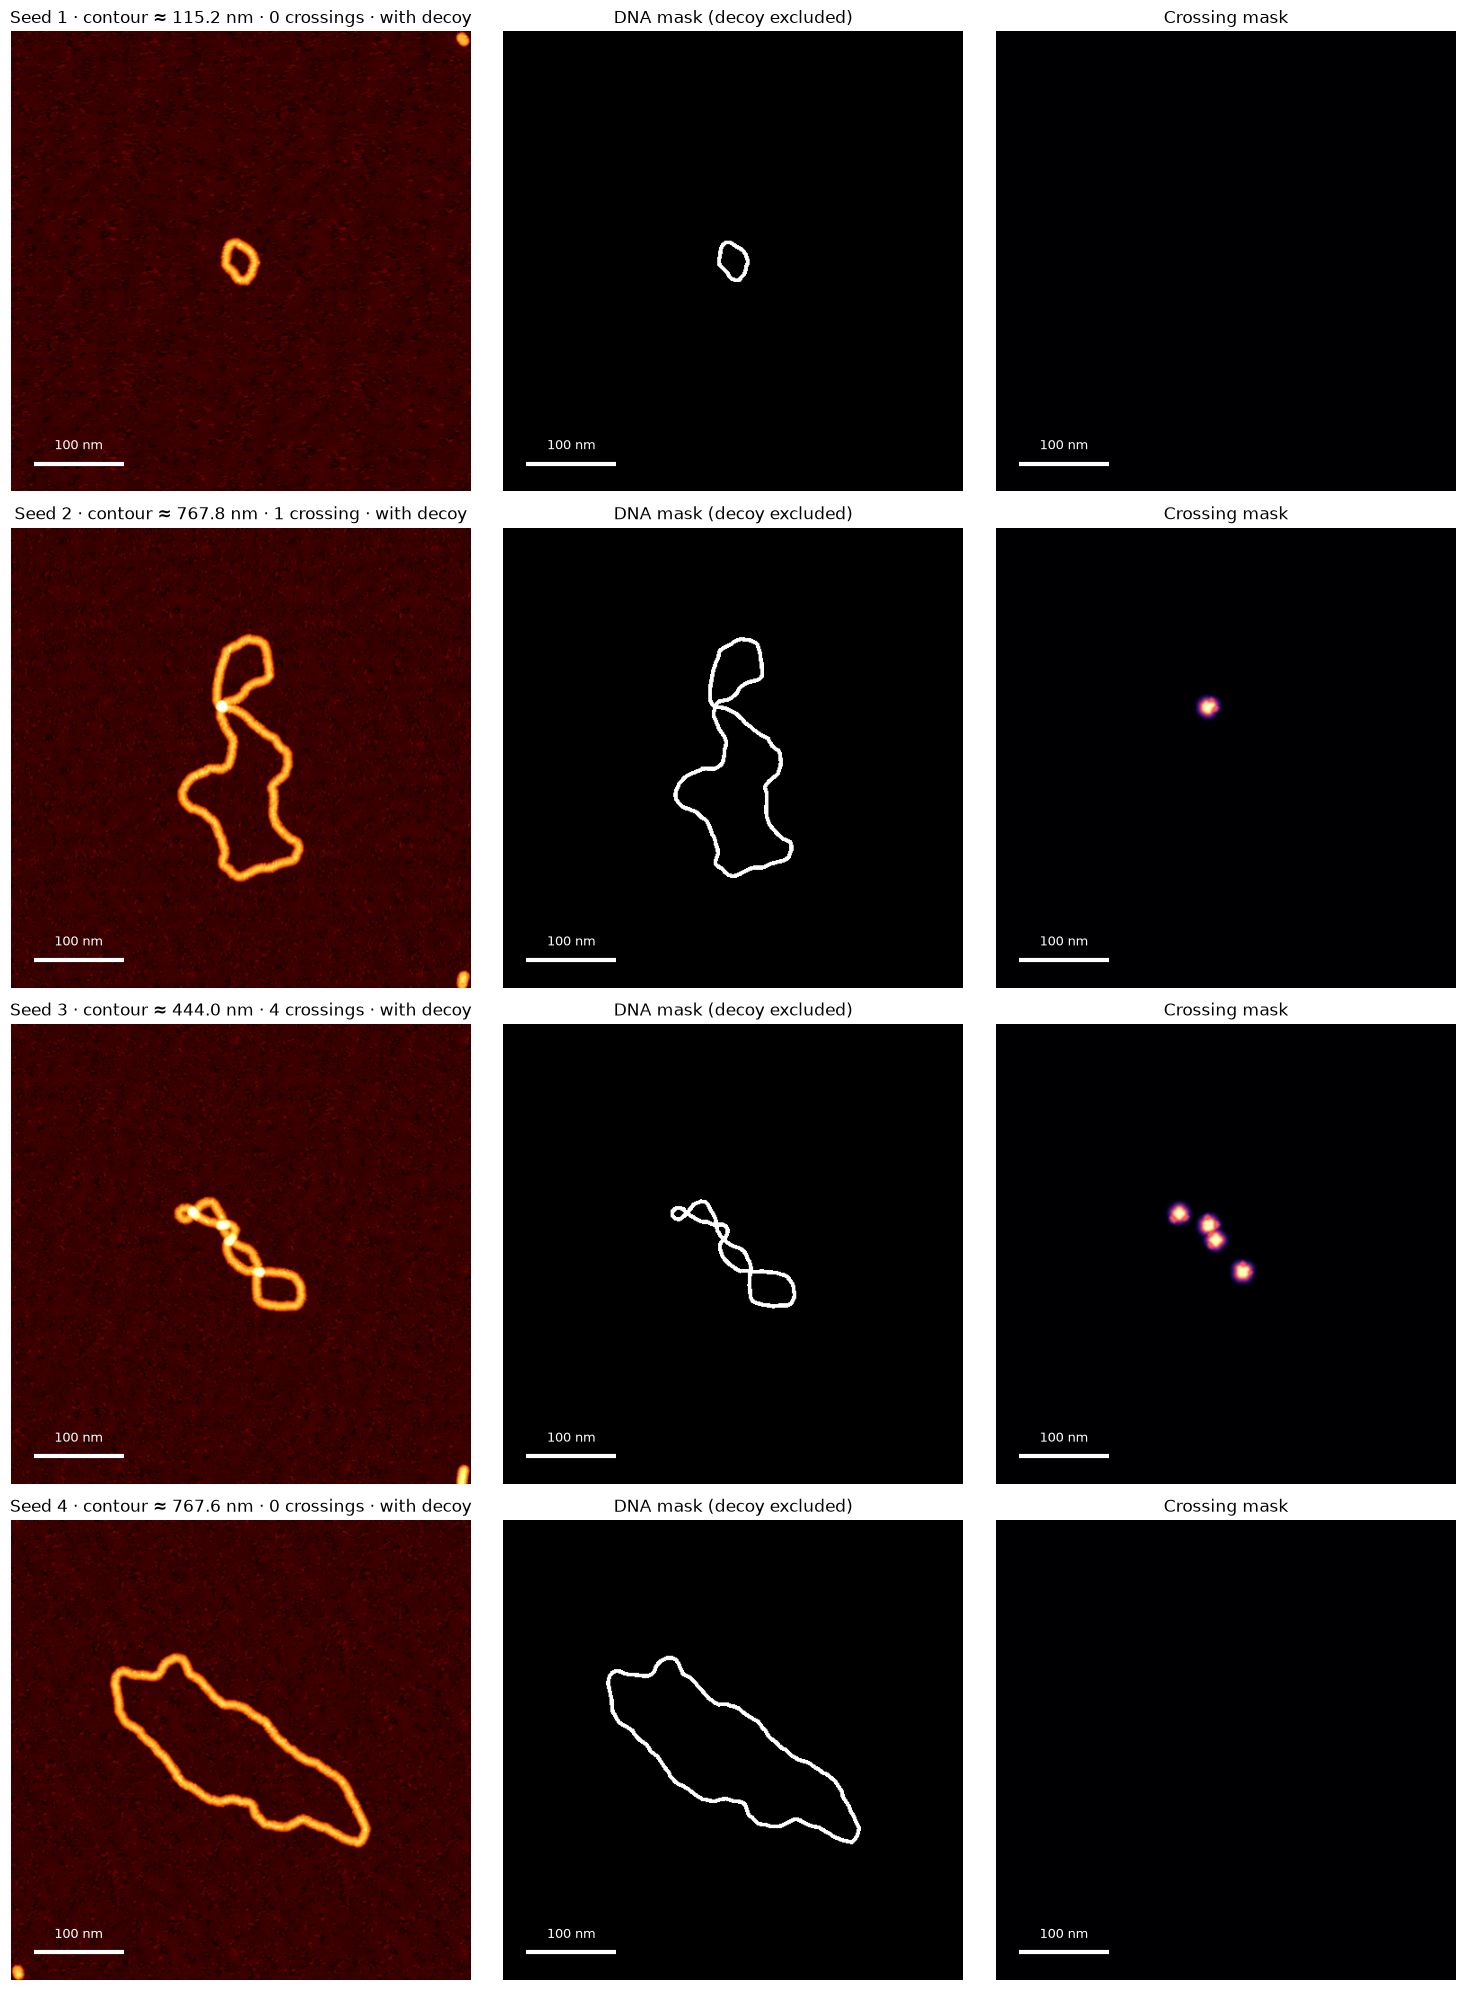

In [8]:
ADD_DECOY = True                                  # True: add a decoy fragment to every sanity-check image
SANITY_SEEDS = [1, 2, 3, 4]                       # one seed per molecule
SANITY_CONTOUR_LENGTHS_NM = [115.26, 768.4, 443.0, 768.4]

sanity_samples = sim.generate_sanity_samples(
    SANITY_SEEDS, SANITY_CONTOUR_LENGTHS_NM, ADD_DECOY, noise_source, noise_asset)
sim.plot_sanity_samples(sanity_samples)

## 7. Benchmarking

This cell estimates how long dataset generation will take on your machine. It prints a system profile (operating system, CPU cores, free memory and, for MD, the OpenMM platforms), generates `BENCH_REPS` molecules while timing each stage (initial chain, MD relaxation or non-MD ring, crossing detection, rendering and masks) and tracks the peak memory. It then projects the total time for `N_SAMPLES` samples. This is useful for comparing machines and checking that GPU acceleration is used.

The timing functions and `PeakMemTracker` memory-tracker class are in `dna_simulation_helpers.py`. This cell only selects the benchmark settings and runs it.

In [9]:
BENCH_SEED = BASE_SEED
BENCH_CONTOUR_LENGTH_NM = CONTOUR_LENGTH_NM
BENCH_REPS = 3

benchmark_results = sim.benchmark_pipeline(
    BENCH_SEED, BENCH_CONTOUR_LENGTH_NM, n_reps=BENCH_REPS,
    total_samples=N_SAMPLES, tracker_cls=sim.PeakMemTracker)

  SYSTEM PROFILE
  OS              : Windows 11
  CPU (logical)   : 24 cores
  RAM available   : 35.5 GB
  OpenMM Platforms: ['Reference', 'CPU', 'OpenCL']
  Mode            : MD (OpenMM)
  Contour length  : 768.4 nm

  RUNNING BENCHMARK
  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  Rep 1/3: 14.09s
  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  Rep 2/3: 14.20s
  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


  Rep 3/3: 13.90s
  Median Wall Time: 14.09 s
    1_chain_init        : 0.00 s
    2_md_relax          : 12.53 s
    3_crossing_detect   : 0.03 s
    4_afm_render_masks  : 1.52 s
  Peak RAM (RSS)  : 368.9 MB
  Projected Total : 0.0 hours for 1 samples


## 8. Dataset generation

Finally, the full dataset is generated. These options can be set:

| Option | Meaning |
|---|---|
| `SAMPLE_TIMEOUT_S` | a seed is skipped if one sample takes longer than this (s), e.g. a stuck MD run |
| `CONTOUR_LENGTH_RANGE_NM` | contour lengths of the molecules (nm) |
| `DNA_DIAMETER_RANGE_NM` | DNA diameter as seen by AFM, i.e. the rendered DNA **height** (nm) |
| `TIP_RADIUS_RANGE_NM` | AFM tip radius (nm) |
| `NOISE_RMS_RANGE_NM` | noise amplitude (RMS height, nm) |
| `EXPORT_PREVIEW_PNGS`, `PREVIEW_PNG_INDICES` | also save PNG previews (image with scale bar) for these sample indices |

**How values are drawn.** Each range option accepts three forms, and every sample draws its own values with a random generator seeded by the sample's seed (so the dataset is reproducible):

* a **list** of discrete values, e.g. `[1.8, 2.3, 2.8]`: each sample picks one of them, each equally likely. A value listed several times is picked proportionally more often; the default `[115.26, 768.4, 768.4, 768.4]` gives 25 % minicircles and 75 % long plasmids, as in the training data;
* a **tuple** `(low, high)`, e.g. `(1.8, 2.8)`: a value drawn uniformly at random between the two;
* a **single number**: the same value for every sample.

The defaults are discrete values spanning the optimised ranges of each pathway.

Samples are generated one at a time in a separate worker process, so a stuck simulation can be stopped after `SAMPLE_TIMEOUT_S`. Seeds that fail (time-out, rejected MD run, molecule too large for the field of view) are skipped, and the next seed is used until `N_SAMPLES` samples exist. Progress is printed every 10 samples. The output folder contains `images/`, `dna_masks/`, `cross_masks/`, `meta/` (coordinates and parameters), optionally `preview_pngs/`, and `manifest.csv`, which links them. Part 2 reads the dataset through this manifest.

In [10]:
SAMPLE_TIMEOUT_S = 60.0                                   # seconds per sample before the seed is skipped
CONTOUR_LENGTH_RANGE_NM = [115.26, 768.4, 768.4, 768.4]   # 25 % minicircles, 75 % plasmids
DNA_DIAMETER_RANGE_NM = [1.8, 2.3, 2.8] if USE_MD else [2.736565473663223]
TIP_RADIUS_RANGE_NM = [6.0, 7.0, 8.0] if USE_MD else [8.662717273203071]
NOISE_RMS_RANGE_NM = [0.05, 0.11, 0.17] if USE_MD else [0.14, 0.16, 0.25]
EXPORT_PREVIEW_PNGS = True
PREVIEW_PNG_INDICES = range(0, 8)     # e.g. range(4, 41), {0, 3, 10, 25} or set()

sim.configure(globals())
for name in ("CONTOUR_LENGTH_RANGE_NM", "DNA_DIAMETER_RANGE_NM", "TIP_RADIUS_RANGE_NM", "NOISE_RMS_RANGE_NM"):
    print(f"{name:24s}: {sim.describe_spec(globals()[name])}")

manifest_path = sim.generate_dataset(
    CONTOUR_LENGTH_RANGE_NM, DNA_DIAMETER_RANGE_NM, TIP_RADIUS_RANGE_NM, NOISE_RMS_RANGE_NM,
    noise_source, noise_asset,
    export_preview_pngs=EXPORT_PREVIEW_PNGS, preview_png_indices=PREVIEW_PNG_INDICES,
    timeout_s=SAMPLE_TIMEOUT_S)

CONTOUR_LENGTH_RANGE_NM : one of 115.26, 768.4, 768.4, 768.4
DNA_DIAMETER_RANGE_NM   : one of 1.8, 2.3, 2.8
TIP_RADIUS_RANGE_NM     : one of 6, 7, 8
NOISE_RMS_RANGE_NM      : one of 0.05, 0.11, 0.17
Starting dataset generation: 1 samples (MD pathway) → C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\dna_dataset_md


Progress: 1/1  (0.3 min elapsed)

Done. Dataset written to: C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\dna_dataset_md
Manifest: C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\dna_dataset_md\manifest.csv


---
# Part 2 — Segmentation with a U-Net

This part sets up a **U-Net that segments DNA in AFM height maps**. It has two outputs: a DNA mask (channel 0) and a crossing map (channel 1). It can:

* **load one of the trained networks** in `checkpoints/` (default, `TRAIN_MODEL = False`). Each was trained on 800 simulated molecules from the matching pathway (MD or non-MD), with the same loss and settings as below;
* **train a new network** (`TRAIN_MODEL = True`) on simulated data.

**Data.** Training and validation use a dataset with a `manifest.csv`:

* the dataset generated in Part 1 (default: `OUT_DIR`);
* a dataset generated earlier with this notebook: set `DATASET_DIR` to its folder;
* your own data: a folder with height maps (`.npy`, in nm), DNA masks and, optionally, crossing masks, plus a `manifest.csv` with the columns `image_npy`, `dna_mask_npy` and (optionally) `cross_mask_npy`, holding paths relative to the folder. An optional `split` column (`train` / `validation`) fixes the split.

If no dataset is found, the simulated-data sections are skipped and the real-data evaluation (section 15) still works with the trained networks.

## 9. Imports and settings

**If you are only running Part 2, first run the imports cell in section 1.1**: it sets `USE_MD`, which chooses between the MD-trained and non-MD-trained networks, and imports NumPy and Matplotlib. Otherwise errors appear further down.

This cell imports everything Part 2 needs that was not imported in Part 1, fixes the random seeds, and sets:

* where the dataset is (`DATASET_DIR`, `manifest_path`);
* which network to use (`ARCHITECTURE`: `"residual"` for the Res-U-Net, `"simple"` for the plain U-Net), whether to train it (`TRAIN_MODEL`) and which checkpoint to load;
* preprocessing: network input size, height normalisation and the crop around each molecule;
* training and loss settings (the values used for the provided checkpoints).

In [11]:
from __future__ import annotations   # lets the classes refer to themselves in type hints

import platform
import random
from typing import Any

import deeplay as dl
import deeptrack as dt
import lightning as L
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
from lightning.pytorch.loggers import CSVLogger
from torch.utils.data import Dataset

import unet_segmentation_helpers as seg   # all Part 2 functions

SEED = 3   # seed for reproducibility
L.seed_everything(SEED, workers=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ── Data ──
DATASET_DIR = Path(globals().get("OUT_DIR", "dna_dataset_md"))   # folder with manifest.csv
manifest_path = DATASET_DIR / "manifest.csv"
VAL_FRACTION = 0.2   # validation share for a random split (if the manifest has no 'split' column)

# ── Network ──
ARCHITECTURE = "residual"   # "residual" (Res-U-Net) or "simple" (plain U-Net)
TRAIN_MODEL = False         # False: load CHECKPOINT_PATH; True: train on DATASET_DIR
CHECKPOINT_PATH = seg.checkpoint_for(USE_MD, ARCHITECTURE)   # provided network for this pathway
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ── Preprocessing (as used for the provided checkpoints) ──
TARGET_SIZE = 512                      # network input size (pixels)
NORMALIZATION_BOUNDS_NM = (-1.0, 5.0)  # heights are clipped to this range (nm) and scaled to 0-1
CROP_PADDING_PX = (20, 60)             # training: crop to the molecule with a random 20-60 px margin
VAL_CROP_PADDING_PX = 40               # validation/evaluation margin; None = use full images

# ── Training and loss ──
MODEL_CFG = dict(in_channels=1, channels=[32, 64, 128, 256], dropout=0.05, norm_groups=8)
TRAIN_CFG = dict(batch_size=4, num_workers=0, max_epochs=50, lr=3e-4)
LOSS_CFG = dict(dna_pos_weight=1.5, dna_loss_weight=3.0, cross_loss_weight=0.02, cross_pos_weight=20.0,
                cross_false_positive_weight=2.0, background_false_positive_weight=0.14, dice_smooth=1.0,
                connectivity_loss_weight=0.5, connectivity_iterations=10)

print(f"Pathway: {'MD' if USE_MD else 'non-MD'} | architecture: {ARCHITECTURE} | "
      f"{'train a new network' if TRAIN_MODEL else f'load {CHECKPOINT_PATH}'} | device: {DEVICE}")
print("Dataset:", manifest_path.resolve(), "(found)" if manifest_path.exists() else "(not found)")

C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\work\colab312_upgrade\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\work\colab312_upgrade\venv312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\work\colab312_upgrade\venv312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\work\colab312_upgrade\venv312\Lib\site-packages\deeptrack\__init__.py:14: UserWarning: TensorFlow is detected in your environment. DeepTrack2 version 2.0++ no longer supports TensorFlow. If you need TensorFlow support, please install the legacy version 1.7 of DeepTrack2:

    pip install deeptrack==1.7

For more details, refer to the DeepTrack documentation.
  warnings.warn(


Seed set to 3


Pathway: MD | architecture: residual | load checkpoints\md_res_unet.pt | device: cpu
Dataset: C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\dna_dataset_md\manifest.csv (found)


## 10. Data: DeepTrack sources and lazy loading

The manifest is read into a list of rows, one per sample, each holding only **file paths** (`seg.manifest_to_records`). The rows are split into training and validation sets (the manifest's `split` column if present, otherwise a random 80 : 20 split) and wrapped in DeepTrack `Source` objects.

**Lazy loading** means that the arrays are read from disk only when the network asks for a sample, so the dataset never needs to fit in memory. For each sample, the DeepTrack pipeline `dt.Value(row) >> dt.Lambda(load_sample)` (`seg.build_pipeline`):

1. loads the height map, the DNA mask and the crossing mask (an all-zero crossing mask if none exists);
2. **crops** the arrays to the molecule: the bounding box of the DNA mask plus a margin. This mimics the grain crops that TopoStats passes to the network on real data, so the molecule appears at the same scale during training and use;
3. applies the same random flips and 90° rotations to image and masks (training only);
4. **normalises** the heights: clipped to −1…5 nm and scaled to 0…1, so a DNA strand of a given height gives the same input in every image;
5. **resizes** everything to 512 × 512, keeping the aspect ratio and padding with the background value (DNA mask: nearest-neighbour, image and crossing mask: bilinear).

The dataset class below connects the pipeline to PyTorch; `dl.DataLoader` then batches the samples.

In [12]:
class DeepTrackSourceDataset(Dataset):
    """PyTorch dataset that evaluates a lazy DeepTrack pipeline per item.

    The DeepTrack source holds one manifest row (file paths) per sample;
    the pipeline built by `seg.build_pipeline` loads, crops, augments,
    normalises and resizes the arrays only when an item is requested.

    Parameters
    ----------
    source: dt.sources.Source
        One manifest row per sample.
    target_size: int
        Network input size in pixels.
    augment: bool
        Random flips and 90° rotations (training only).
    bounds: tuple[float, float], optional
        Height normalisation bounds in nm. Defaults to
        ``NORMALIZATION_BOUNDS_NM``.
    crop_padding_px: int | tuple[int, int] | None, optional
        Crop each image to its molecule with this margin in pixels; a
        ``(low, high)`` tuple draws the margin at random. Defaults to
        `None`, which keeps the full image.

    Attributes
    ----------
    source: dt.sources.Source
        The manifest rows.
    pipeline: dt.Feature
        The lazy loading pipeline.

    Methods
    -------
    `__len__() -> int`
        Number of samples.
    `__getitem__(index) -> tuple[torch.Tensor, torch.Tensor]`
        Image ``(1, H, W)`` and targets ``(2, H, W)`` of one sample.

    Examples
    --------
    >>> rows = [{
    ...     "image_path": "../common-assets/real-test-data/image_5.npy",
    ...     "dna_path": "../common-assets/real-test-data/mask_5.npy",
    ... }]
    >>> dataset = DeepTrackSourceDataset(
    ...     dt.sources.Source(samples=rows), 256, augment=False,
    ...     crop_padding_px=40,
    ... )
    >>> image, target = dataset[0]
    >>> len(dataset), tuple(image.shape), tuple(target.shape)
    (1, (1, 256, 256), (2, 256, 256))

    """

    source: dt.sources.Source
    pipeline: dt.Feature

    def __init__(
        self: DeepTrackSourceDataset,
        source: dt.sources.Source,
        target_size: int,
        augment: bool,
        bounds: tuple[float, float] = NORMALIZATION_BOUNDS_NM,
        crop_padding_px: int | tuple[int, int] | None = None,
    ) -> None:
        """Build the pipeline for a source.

        Parameters
        ----------
        source: dt.sources.Source
            One manifest row per sample.
        target_size: int
            Network input size in pixels.
        augment: bool
            Random flips and 90° rotations.
        bounds: tuple[float, float], optional
            Height normalisation bounds in nm. Defaults to
            ``NORMALIZATION_BOUNDS_NM``.
        crop_padding_px: int | tuple[int, int] | None, optional
            Crop margin in pixels. Defaults to `None`.

        """

        self.source = source
        self.pipeline = seg.build_pipeline(
            source, target_size, augment, bounds, crop_padding_px
        )

    def __len__(self: DeepTrackSourceDataset) -> int:
        """Return the number of samples.

        Returns
        -------
        int
            Number of manifest rows in the source.

        """

        return len(self.source)

    @staticmethod
    def _to_tensor(array: Any) -> torch.Tensor:
        """Convert an array to a contiguous, finite float32 tensor.

        Flips and rotations leave negative strides, which PyTorch does
        not accept.

        Parameters
        ----------
        array: Any
            Array-like output of the pipeline.

        Returns
        -------
        torch.Tensor
            The array as a float32 tensor.

        """

        array = np.nan_to_num(np.asarray(array, dtype=np.float32))
        return torch.from_numpy(np.ascontiguousarray(array))

    def __getitem__(
        self: DeepTrackSourceDataset,
        index: int,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Load one sample through the pipeline.

        The pipeline is updated first, so the random crop margin and
        augmentation are drawn anew every time.

        Parameters
        ----------
        index: int
            Sample index.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor]
            Image ``(1, H, W)`` and targets ``(2, H, W)`` (DNA,
            crossings).

        Raises
        ------
        TypeError
            If the pipeline does not return an image and a target.

        """

        self.pipeline.update()
        result = self.pipeline(self.source[index])
        if not isinstance(result, (tuple, list)) or len(result) != 2:
            raise TypeError("The pipeline must return (image, target).")
        image, target = result
        return self._to_tensor(image), self._to_tensor(target)


train_loader = val_loader = None
if manifest_path.exists():
    manifest_df = pd.read_csv(manifest_path)
    all_records = seg.manifest_to_records(manifest_df, manifest_path.parent)
    train_records, val_records = seg.split_records(all_records, VAL_FRACTION, SEED)
    train_source = dt.sources.Source(samples=train_records)
    val_source = dt.sources.Source(samples=val_records)

    train_dataset = DeepTrackSourceDataset(train_source, TARGET_SIZE, augment=True,
                                           bounds=NORMALIZATION_BOUNDS_NM, crop_padding_px=CROP_PADDING_PX)
    val_dataset = DeepTrackSourceDataset(val_source, TARGET_SIZE, augment=False,
                                         bounds=NORMALIZATION_BOUNDS_NM, crop_padding_px=VAL_CROP_PADDING_PX)
    loader_kw = dict(batch_size=TRAIN_CFG["batch_size"], num_workers=TRAIN_CFG["num_workers"],
                     pin_memory=torch.cuda.is_available())
    train_loader = dl.DataLoader(train_dataset, shuffle=True, **loader_kw)
    val_loader = dl.DataLoader(val_dataset, shuffle=False, **loader_kw)

    image_batch, target_batch = next(iter(train_loader))
    print(f"Samples: {len(all_records)} total | {len(train_records)} training | {len(val_records)} validation")
    print("image batch:", tuple(image_batch.shape), "| target batch:", tuple(target_batch.shape),
          "| target channels: DNA = 0, crossings = 1")
else:
    print(f"No manifest at {manifest_path}. Generate a dataset in Part 1 or set DATASET_DIR; "
          "sections 13-14 then skip the simulated data, section 15 still works.")

Samples: 1 total | 1 training | 1 validation
image batch: (1, 1, 512, 512) | target batch: (1, 2, 512, 512) | target channels: DNA = 0, crossings = 1


## 11. Loss functions and metrics

The network outputs two logit maps $z$, turned into probabilities $p = \sigma(z)$ (sigmoid): $p_{\mathrm{DNA}}$ (channel 0) and $p_{\times}$ for crossings (channel 1). Targets are the DNA mask $y_{\mathrm{DNA}} \in \{0,1\}$ and the soft crossing mask $y_{\times} \in [0,1]$. All sums run over the pixels of one image, and losses are averaged over the images of a batch.

**DNA loss**: three complementary terms:

* *Weighted binary cross-entropy*, per pixel, with DNA pixels up-weighted ($w_+ = 1.5$) because DNA covers only a few percent of an image:
  $\mathcal{L}_{\mathrm{BCE}} = -\overline{\,w_+\, y \log p + (1-y)\log(1-p)\,}$
* *Dice loss*, the overlap between prediction and target, insensitive to how much background there is:
  $\mathcal{L}_{\mathrm{Dice}} = 1 - \dfrac{2\sum p\,y + 1}{\sum p + \sum y + 1}$
* *clDice loss* ([Shit et al., CVPR 2021](https://arxiv.org/abs/2003.07311)), which rewards a **connected centre line**, the property that matters for tracing a molecule. With $S(\cdot)$ a differentiable skeleton (repeated soft erosion and opening, `seg.soft_skeletonize`):
  $T_{\mathrm{prec}} = \dfrac{\sum S(p)\,y}{\sum S(p)}, \quad T_{\mathrm{sens}} = \dfrac{\sum S(y)\,p}{\sum S(y)}, \quad \mathcal{L}_{\mathrm{clDice}} = 1 - \dfrac{2\,T_{\mathrm{prec}} T_{\mathrm{sens}}}{T_{\mathrm{prec}} + T_{\mathrm{sens}}}$

$\mathcal{L}_{\mathrm{DNA}} = 0.4\,\mathcal{L}_{\mathrm{BCE}} + 0.6\,\mathcal{L}_{\mathrm{Dice}} + 0.5\,\mathcal{L}_{\mathrm{clDice}}$

**Crossing loss**: crossings are rare and small, so a *focal* cross-entropy concentrates on the pixels the network gets wrong ($p_t$ is the probability of the correct class), with crossing pixels weighted by $1 + 20\,y_\times$. Two penalties discourage crossing probability on ordinary DNA ($\Omega_{\mathrm{DNA}}$: DNA pixels outside crossings) and on background ($\Omega_{\mathrm{bg}}$):

$\mathcal{L}_{\times} = \overline{(1+20\,y_\times)(1-p_t)^2\,\mathrm{BCE}} + 2.0\,\overline{p_\times^2}\big|_{\Omega_{\mathrm{DNA}}} + 0.14\,\overline{p_\times^2}\big|_{\Omega_{\mathrm{bg}}}$

**Total**: $\mathcal{L} = 3.0\,\mathcal{L}_{\mathrm{DNA}} + 0.02\,\mathcal{L}_{\times}$

**Metrics** (DNA channel, thresholded at 0.5; $P$ = predicted DNA pixels, $T$ = true DNA pixels):

| Metric | Formula | Meaning |
|---|---|---|
| Dice | $\dfrac{2\lvert P\cap T\rvert}{\lvert P\rvert+\lvert T\rvert}$ | overlap, 1 = perfect |
| IoU (Jaccard) | $\dfrac{\lvert P\cap T\rvert}{\lvert P\cup T\rvert}$ | stricter overlap, 1 = perfect (IoU = Dice / (2 − Dice)) |
| Precision | $\dfrac{\lvert P\cap T\rvert}{\lvert P\rvert}$ | how much of the prediction is DNA |
| Recall | $\dfrac{\lvert P\cap T\rvert}{\lvert T\rvert}$ | how much of the DNA was found |

The loss and the two logged metrics are classes; the building blocks (soft skeleton, masked means, scores) are in `unet_segmentation_helpers.py`.

In [13]:
class DNACrossingLoss(nn.Module):
    """Two-task loss: DNA segmentation and crossing detection.

    Channel 0 of the prediction and the target is DNA, channel 1 the
    crossings. For each image of a batch,

    - the DNA loss is 0.4 BCE (DNA pixels weighted by `dna_pos_weight`)
      + 0.6 Dice loss + `connectivity_loss_weight` clDice loss;
    - the crossing loss is a focal BCE (crossing pixels weighted by
      1 + `cross_pos_weight` times the target) plus penalties on crossing
      probability on ordinary DNA and on background.

    The total is `dna_loss_weight` times the DNA loss plus
    `cross_loss_weight` times the crossing loss. Images whose crossings
    are not labelled only contribute to the DNA loss. Section 11 gives the
    equations.

    Parameters
    ----------
    dna_pos_weight: float, optional
        Weight of DNA pixels in the BCE. Defaults to 1.5.
    dna_loss_weight: float, optional
        Weight of the DNA loss in the total. Defaults to 3.0.
    cross_loss_weight: float, optional
        Weight of the crossing loss in the total. Defaults to 0.02.
    cross_pos_weight: float, optional
        Extra weight of crossing pixels in the focal BCE. Defaults to 20.0.
    cross_false_positive_weight: float, optional
        Penalty on crossing probability on ordinary DNA. Defaults to 2.0.
    background_false_positive_weight: float, optional
        Penalty on crossing probability on background. Defaults to 0.14.
    dice_smooth: float, optional
        Smoothing of the Dice and clDice ratios. Defaults to 1.0.
    connectivity_loss_weight: float, optional
        Weight of the clDice loss. Defaults to 0.5.
    connectivity_iterations: int, optional
        Erosion steps of the soft skeleton (`seg.soft_skeletonize`).
        Defaults to 10.

    Attributes
    ----------
    config: dict[str, float]
        All settings, by parameter name.

    Methods
    -------
    `forward(prediction, target, ...) -> torch.Tensor | tuple`
        Loss of a batch and, optionally, its parts.

    Examples
    --------
    >>> loss_fn = DNACrossingLoss()
    >>> prediction = torch.zeros(2, 2, 32, 32)
    >>> target = torch.zeros(2, 2, 32, 32)
    >>> target[:, 0, 10:20, 5:25] = 1
    >>> loss = loss_fn(prediction, target)
    >>> loss.ndim, bool(loss > 0)
    (0, True)

    """

    config: dict[str, float]

    def __init__(
        self: DNACrossingLoss,
        dna_pos_weight: float = 1.5,
        dna_loss_weight: float = 3.0,
        cross_loss_weight: float = 0.02,
        cross_pos_weight: float = 20.0,
        cross_false_positive_weight: float = 2.0,
        background_false_positive_weight: float = 0.14,
        dice_smooth: float = 1.0,
        connectivity_loss_weight: float = 0.5,
        connectivity_iterations: int = 10,
    ) -> None:
        """Store the loss settings.

        Parameters
        ----------
        dna_pos_weight: float, optional
            Weight of DNA pixels in the BCE. Defaults to 1.5.
        dna_loss_weight: float, optional
            Weight of the DNA loss. Defaults to 3.0.
        cross_loss_weight: float, optional
            Weight of the crossing loss. Defaults to 0.02.
        cross_pos_weight: float, optional
            Extra weight of crossing pixels. Defaults to 20.0.
        cross_false_positive_weight: float, optional
            Penalty on ordinary DNA. Defaults to 2.0.
        background_false_positive_weight: float, optional
            Penalty on background. Defaults to 0.14.
        dice_smooth: float, optional
            Smoothing of the ratios. Defaults to 1.0.
        connectivity_loss_weight: float, optional
            Weight of the clDice loss. Defaults to 0.5.
        connectivity_iterations: int, optional
            Erosion steps of the soft skeleton. Defaults to 10.

        """

        super().__init__()
        self.config = dict(
            dna_pos_weight=dna_pos_weight,
            dna_loss_weight=dna_loss_weight,
            cross_loss_weight=cross_loss_weight,
            cross_pos_weight=cross_pos_weight,
            cross_false_positive_weight=cross_false_positive_weight,
            background_false_positive_weight=(
                background_false_positive_weight
            ),
            dice_smooth=dice_smooth,
            connectivity_loss_weight=connectivity_loss_weight,
            connectivity_iterations=int(connectivity_iterations),
        )

    def forward(
        self: DNACrossingLoss,
        prediction: torch.Tensor,
        target: torch.Tensor,
        crossing_labeled: torch.Tensor | list[bool] | None = None,
        return_parts: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, dict[str, torch.Tensor]]:
        """Compute the loss of a batch.

        Parameters
        ----------
        prediction: torch.Tensor
            Logits of shape ``(B, 2, H, W)`` (DNA, crossings).
        target: torch.Tensor
            Targets of the same shape: binary DNA mask and soft crossing
            mask.
        crossing_labeled: torch.Tensor | list[bool] | None, optional
            Whether the crossings of each image are labelled. Defaults to
            `None` (all labelled).
        return_parts: bool, optional
            Also return the individual terms. Defaults to `False`.

        Returns
        -------
        torch.Tensor | tuple[torch.Tensor, dict[str, torch.Tensor]]
            The total loss (a scalar) and, with ``return_parts``, a
            dictionary with ``dna_loss``, ``crossing_loss``, ``dna_bce``,
            ``dna_dice_loss`` and ``dna_cldice_loss``.

        Examples
        --------
        With all logits 0, every probability is 0.5:

        >>> loss_fn = DNACrossingLoss()
        >>> prediction = torch.zeros(1, 2, 32, 32)
        >>> target = torch.zeros(1, 2, 32, 32)
        >>> target[:, 0, 10:20, 5:25] = 1
        >>> _, parts = loss_fn(prediction, target, return_parts=True)
        >>> round(float(parts["dna_dice_loss"]), 3)
        0.718

        """

        p, y, cfg = prediction.float(), target.float(), self.config
        z, dna = p[:, :1], y[:, :1]
        probability = z.sigmoid()
        smooth = cfg["dice_smooth"]

        # DNA: weighted BCE + Dice + clDice (connectivity of the centre
        # line).
        bce = seg.mean_per_sample(
            F.binary_cross_entropy_with_logits(
                z,
                dna,
                pos_weight=z.new_tensor(cfg["dna_pos_weight"]),
                reduction="none",
            )
        )
        overlap = (probability * dna).flatten(1).sum(1)
        size_pred = probability.flatten(1).sum(1)
        size_true = dna.flatten(1).sum(1)
        dice = 1 - (2 * overlap + smooth) / (size_pred + size_true + smooth)
        iterations = cfg["connectivity_iterations"]
        skeleton_pred = seg.soft_skeletonize(probability, iterations)
        skeleton_true = seg.soft_skeletonize(dna, iterations)
        topology_precision = (
            (skeleton_pred * dna).flatten(1).sum(1) + smooth
        ) / (skeleton_pred.flatten(1).sum(1) + smooth)
        topology_sensitivity = (
            (skeleton_true * probability).flatten(1).sum(1) + smooth
        ) / (skeleton_true.flatten(1).sum(1) + smooth)
        cldice = 1 - 2 * topology_precision * topology_sensitivity / (
            topology_precision + topology_sensitivity
        ).clamp_min(1e-12)
        dna_loss = (
            0.4 * bce + 0.6 * dice + cfg["connectivity_loss_weight"] * cldice
        ).mean()

        # Crossings: focal BCE + false-positive penalties, only for the
        # images whose crossings are labelled.
        if crossing_labeled is None:
            available = torch.ones(
                p.shape[0], device=p.device, dtype=torch.bool
            )
        else:
            available = torch.as_tensor(
                crossing_labeled, device=p.device, dtype=torch.bool
            )
        cross_loss = p.new_zeros(())
        if available.any() and cfg["cross_loss_weight"]:
            cross_z, cross_y = p[available, 1:2], y[available, 1:2]
            q = cross_z.sigmoid()
            pt = q * cross_y + (1 - q) * (1 - cross_y)
            focal = (
                (1 + cfg["cross_pos_weight"] * cross_y)
                * (1 - pt).square()
                * F.binary_cross_entropy_with_logits(
                    cross_z, cross_y, reduction="none"
                )
            )
            region = (cross_y > 0.05).float()
            non_crossing_dna = y[available, :1] * (1 - region)
            cross_loss = (
                seg.mean_per_sample(focal)
                + cfg["cross_false_positive_weight"]
                * seg.masked_mean(q.square(), non_crossing_dna)
                + cfg["background_false_positive_weight"]
                * seg.masked_mean(q.square(), 1 - region)
            ).mean()

        total = (
            cfg["dna_loss_weight"] * dna_loss
            + cfg["cross_loss_weight"] * cross_loss
        )
        if return_parts:
            return total, dict(
                dna_loss=dna_loss.detach(),
                crossing_loss=cross_loss.detach(),
                dna_bce=bce.mean().detach(),
                dna_dice_loss=dice.mean().detach(),
                dna_cldice_loss=cldice.mean().detach(),
            )
        return total


class DNAIouMetric(torchmetrics.Metric):
    """IoU of the thresholded DNA channel, accumulated over an epoch.

    The intersection and union of the predicted DNA pixels (probability
    above `threshold`) and the true DNA pixels are summed over all batches
    before the ratio is taken.

    Parameters
    ----------
    threshold: float, optional
        DNA probability threshold. Defaults to 0.5.
    smooth: float, optional
        Added to the numerator and the denominator. Defaults to 1.0.

    Attributes
    ----------
    full_state_update: bool
        `False`: `update()` does not need the full metric state (a
        torchmetrics setting).
    threshold: float
        DNA probability threshold.
    smooth: float
        Smoothing term.
    intersection: torch.Tensor
        Summed intersection.
    union: torch.Tensor
        Summed union.

    Methods
    -------
    `update(preds, target) -> None`
        Add one batch.
    `compute() -> torch.Tensor`
        IoU of everything added since the last reset.

    Examples
    --------
    Predicted DNA covers two rows and true DNA one of them:

    >>> metric = DNAIouMetric()
    >>> logits = torch.full((1, 2, 4, 4), -5.0)
    >>> logits[:, 0, :2] = 5.0
    >>> target = torch.zeros(1, 2, 4, 4)
    >>> target[:, 0, :1] = 1
    >>> metric.update(logits, target)
    >>> round(float(metric.compute()), 3)
    0.556

    """

    full_state_update: bool = False
    threshold: float
    smooth: float
    intersection: torch.Tensor
    union: torch.Tensor

    def __init__(
        self: DNAIouMetric,
        threshold: float = 0.5,
        smooth: float = 1.0,
    ) -> None:
        """Create the metric with zero states.

        Parameters
        ----------
        threshold: float, optional
            DNA probability threshold. Defaults to 0.5.
        smooth: float, optional
            Smoothing term. Defaults to 1.0.

        """

        super().__init__()
        self.threshold, self.smooth = float(threshold), float(smooth)
        self.add_state(
            "intersection", default=torch.tensor(0.0), dist_reduce_fx="sum"
        )
        self.add_state(
            "union", default=torch.tensor(0.0), dist_reduce_fx="sum"
        )

    def update(
        self: DNAIouMetric,
        preds: torch.Tensor,
        target: torch.Tensor,
    ) -> None:
        """Add the intersection and union of one batch.

        Parameters
        ----------
        preds: torch.Tensor
            Logits of shape ``(B, 2, H, W)``; channel 0 is used.
        target: torch.Tensor
            Targets of the same shape; channel 0 is the DNA mask.

        Returns
        -------
        None
            The states are updated.

        Examples
        --------
        >>> metric = DNAIouMetric()
        >>> metric.update(torch.zeros(1, 2, 4, 4), torch.ones(1, 2, 4, 4))
        >>> float(metric.intersection), float(metric.union)
        (0.0, 16.0)

        """

        pred = (torch.sigmoid(preds[:, 0:1]) > self.threshold).float()
        truth = target[:, 0:1].float()
        inter = torch.sum(pred * truth)
        self.intersection += inter
        self.union += torch.sum(pred) + torch.sum(truth) - inter

    def compute(self: DNAIouMetric) -> torch.Tensor:
        """IoU of everything added since the last reset.

        Returns
        -------
        torch.Tensor
            (intersection + smooth) / (union + smooth).

        Examples
        --------
        >>> metric = DNAIouMetric()
        >>> metric.update(torch.ones(1, 2, 4, 4), torch.ones(1, 2, 4, 4))
        >>> float(metric.compute())
        1.0

        """

        return (self.intersection + self.smooth) / (self.union + self.smooth)


class DNADiceMetric(torchmetrics.Metric):
    """Dice score of the thresholded DNA channel, accumulated over an epoch.

    The intersection and the sizes of the predicted DNA pixels
    (probability above `threshold`) and the true DNA pixels are summed
    over all batches before the ratio is taken.

    Parameters
    ----------
    threshold: float, optional
        DNA probability threshold. Defaults to 0.5.
    smooth: float, optional
        Added to the numerator and the denominator. Defaults to 1.0.

    Attributes
    ----------
    full_state_update: bool
        `False`: `update()` does not need the full metric state (a
        torchmetrics setting).
    threshold: float
        DNA probability threshold.
    smooth: float
        Smoothing term.
    intersection: torch.Tensor
        Summed intersection.
    total: torch.Tensor
        Summed sizes of prediction and truth.

    Methods
    -------
    `update(preds, target) -> None`
        Add one batch.
    `compute() -> torch.Tensor`
        Dice score of everything added since the last reset.

    Examples
    --------
    Predicted DNA covers two rows and true DNA one of them:

    >>> metric = DNADiceMetric()
    >>> logits = torch.full((1, 2, 4, 4), -5.0)
    >>> logits[:, 0, :2] = 5.0
    >>> target = torch.zeros(1, 2, 4, 4)
    >>> target[:, 0, :1] = 1
    >>> metric.update(logits, target)
    >>> round(float(metric.compute()), 3)
    0.692

    """

    full_state_update: bool = False
    threshold: float
    smooth: float
    intersection: torch.Tensor
    total: torch.Tensor

    def __init__(
        self: DNADiceMetric,
        threshold: float = 0.5,
        smooth: float = 1.0,
    ) -> None:
        """Create the metric with zero states.

        Parameters
        ----------
        threshold: float, optional
            DNA probability threshold. Defaults to 0.5.
        smooth: float, optional
            Smoothing term. Defaults to 1.0.

        """

        super().__init__()
        self.threshold, self.smooth = float(threshold), float(smooth)
        self.add_state(
            "intersection", default=torch.tensor(0.0), dist_reduce_fx="sum"
        )
        self.add_state(
            "total", default=torch.tensor(0.0), dist_reduce_fx="sum"
        )

    def update(
        self: DNADiceMetric,
        preds: torch.Tensor,
        target: torch.Tensor,
    ) -> None:
        """Add the intersection and sizes of one batch.

        Parameters
        ----------
        preds: torch.Tensor
            Logits of shape ``(B, 2, H, W)``; channel 0 is used.
        target: torch.Tensor
            Targets of the same shape; channel 0 is the DNA mask.

        Returns
        -------
        None
            The states are updated.

        Examples
        --------
        >>> metric = DNADiceMetric()
        >>> metric.update(torch.zeros(1, 2, 4, 4), torch.ones(1, 2, 4, 4))
        >>> float(metric.intersection), float(metric.total)
        (0.0, 16.0)

        """

        pred = (torch.sigmoid(preds[:, 0:1]) > self.threshold).float()
        truth = target[:, 0:1].float()
        self.intersection += torch.sum(pred * truth)
        self.total += torch.sum(pred) + torch.sum(truth)

    def compute(self: DNADiceMetric) -> torch.Tensor:
        """Dice score of everything added since the last reset.

        Returns
        -------
        torch.Tensor
            (2 intersection + smooth) / (total + smooth).

        Examples
        --------
        >>> metric = DNADiceMetric()
        >>> metric.update(torch.ones(1, 2, 4, 4), torch.ones(1, 2, 4, 4))
        >>> float(metric.compute())
        1.0

        """

        return (2 * self.intersection + self.smooth) / (
            self.total + self.smooth
        )


loss_fn = DNACrossingLoss(**LOSS_CFG)
print("Loss settings:", loss_fn.config)

Loss settings: {'dna_pos_weight': 1.5, 'dna_loss_weight': 3.0, 'cross_loss_weight': 0.02, 'cross_pos_weight': 20.0, 'cross_false_positive_weight': 2.0, 'background_false_positive_weight': 0.14, 'dice_smooth': 1.0, 'connectivity_loss_weight': 0.5, 'connectivity_iterations': 10}


## 12. The U-Net

A **U-Net** is a convolutional network for image segmentation. An *encoder* repeatedly convolves and down-samples the image to capture context (is this a strand? where does it go?), and a *decoder* up-samples back to full resolution. *Skip connections* pass the encoder's detailed features to the decoder at every level, so the output is both context-aware and pixel-accurate. Here the U-Net turns an AFM height map into a per-pixel DNA probability and a per-pixel crossing probability.

Two architectures are provided, each with trained checkpoints for both pathways:

* **Res-U-Net** (`ARCHITECTURE = "residual"`, 7.6 M parameters): residual blocks with GroupNorm at every level, a bottleneck, and two separate output heads for DNA and crossings;
* **simple U-Net** (`ARCHITECTURE = "simple"`, 2.1 M parameters): one convolution per level and a single two-channel output layer, identical to Deeplay's `UNet2d(1, [32, 64, 128, 256], 2)`.

The network is wrapped in a Deeplay `Regressor` together with the loss, the metrics and the Adam optimiser.

In [14]:
class ResidualBlock(nn.Module):
    """Two 3×3 convolutions with GroupNorm and a shortcut connection.

    The main path is convolution, GroupNorm, ReLU, dropout, convolution
    and GroupNorm. The shortcut is the identity when the channel count is
    unchanged and a 1×1 convolution otherwise. Their sum is passed through
    a ReLU.

    Parameters
    ----------
    in_channels: int
        Input channels.
    out_channels: int
        Output channels.
    dropout: float, optional
        Dropout probability between the convolutions. Defaults to 0.05.
    norm_groups: int, optional
        Preferred number of GroupNorm groups (see
        `seg.valid_group_count`). Defaults to 8.

    Attributes
    ----------
    main: nn.Sequential
        The main path.
    shortcut: nn.Module
        The shortcut: identity or 1×1 convolution.

    Methods
    -------
    `forward(x) -> torch.Tensor`
        Apply the block.

    Examples
    --------
    >>> block = ResidualBlock(1, 32)
    >>> tuple(block(torch.rand(2, 1, 64, 64)).shape)
    (2, 32, 64, 64)

    """

    main: nn.Sequential
    shortcut: nn.Module

    def __init__(
        self: ResidualBlock,
        in_channels: int,
        out_channels: int,
        dropout: float = 0.05,
        norm_groups: int = 8,
    ) -> None:
        """Create the layers.

        Parameters
        ----------
        in_channels: int
            Input channels.
        out_channels: int
            Output channels.
        dropout: float, optional
            Dropout probability. Defaults to 0.05.
        norm_groups: int, optional
            Preferred number of GroupNorm groups. Defaults to 8.

        """

        super().__init__()
        groups = seg.valid_group_count(out_channels, norm_groups)
        self.main = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(dropout) if dropout > 0 else nn.Identity(),
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, out_channels),
        )
        if in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels, kernel_size=1, bias=False
            )

    def forward(self: ResidualBlock, x: torch.Tensor) -> torch.Tensor:
        """Apply the block.

        Parameters
        ----------
        x: torch.Tensor
            Input of shape ``(B, in_channels, H, W)``.

        Returns
        -------
        torch.Tensor
            Output of shape ``(B, out_channels, H, W)``.

        Examples
        --------
        >>> block = ResidualBlock(32, 32)
        >>> tuple(block(torch.rand(1, 32, 16, 16)).shape)
        (1, 32, 16, 16)

        """

        return F.relu(self.main(x) + self.shortcut(x), inplace=True)


class UpBlock(nn.Module):
    """Decoder step of the Res-U-Net.

    The input is upsampled (bilinear) to the size of the skip connection,
    its channels are reduced with a 1×1 convolution, the skip connection
    is concatenated, and a :class:`ResidualBlock` combines the two.

    Parameters
    ----------
    in_channels: int
        Channels of the input from the deeper level.
    skip_channels: int
        Channels of the skip connection.
    out_channels: int
        Output channels.
    dropout: float, optional
        Dropout probability of the residual block. Defaults to 0.05.
    norm_groups: int, optional
        Preferred number of GroupNorm groups. Defaults to 8.

    Attributes
    ----------
    reduce_channels: nn.Conv2d
        The 1×1 convolution applied after upsampling.
    block: ResidualBlock
        The residual block applied after concatenation.

    Methods
    -------
    `forward(x, skip) -> torch.Tensor`
        Upsample, concatenate and apply the block.

    Examples
    --------
    >>> up = UpBlock(64, 32, 32)
    >>> x, skip = torch.rand(1, 64, 16, 16), torch.rand(1, 32, 32, 32)
    >>> tuple(up(x, skip).shape)
    (1, 32, 32, 32)

    """

    reduce_channels: nn.Conv2d
    block: ResidualBlock

    def __init__(
        self: UpBlock,
        in_channels: int,
        skip_channels: int,
        out_channels: int,
        dropout: float = 0.05,
        norm_groups: int = 8,
    ) -> None:
        """Create the layers.

        Parameters
        ----------
        in_channels: int
            Channels of the input from the deeper level.
        skip_channels: int
            Channels of the skip connection.
        out_channels: int
            Output channels.
        dropout: float, optional
            Dropout probability. Defaults to 0.05.
        norm_groups: int, optional
            Preferred number of GroupNorm groups. Defaults to 8.

        """

        super().__init__()
        self.reduce_channels = nn.Conv2d(
            in_channels, out_channels, kernel_size=1
        )
        self.block = ResidualBlock(
            out_channels + skip_channels, out_channels, dropout, norm_groups
        )

    def forward(
        self: UpBlock,
        x: torch.Tensor,
        skip: torch.Tensor,
    ) -> torch.Tensor:
        """Upsample, concatenate the skip connection and apply the block.

        Parameters
        ----------
        x: torch.Tensor
            Input from the deeper level, ``(B, in_channels, h, w)``.
        skip: torch.Tensor
            Skip connection, ``(B, skip_channels, H, W)``.

        Returns
        -------
        torch.Tensor
            Output of shape ``(B, out_channels, H, W)``.

        Examples
        --------
        >>> up = UpBlock(64, 32, 32)
        >>> x, skip = torch.rand(1, 64, 8, 8), torch.rand(1, 32, 16, 16)
        >>> tuple(up(x, skip).shape)
        (1, 32, 16, 16)

        """

        x = F.interpolate(
            x, size=skip.shape[-2:], mode="bilinear", align_corners=False
        )
        x = self.reduce_channels(x)
        return self.block(torch.cat([x, skip], dim=1))


class ResUNetTwoHeads(nn.Module):
    """Residual U-Net with two output heads (DNA and crossings).

    The encoder has one :class:`ResidualBlock` per level (``channels``)
    with max-pooling between levels, followed by a bottleneck with twice
    the deepest channel count. The decoder mirrors the encoder with
    :class:`UpBlock` s. Two small heads turn the final features into one
    DNA logit map and one crossing logit map, returned as channels 0 and
    1.

    Parameters
    ----------
    in_channels: int, optional
        Input channels. Defaults to 1.
    channels: list[int] | tuple[int, ...], optional
        Channels of the encoder levels. Defaults to
        ``(32, 64, 128, 256)``.
    dropout: float, optional
        Dropout probability of the residual blocks. Defaults to 0.05.
    norm_groups: int, optional
        Preferred number of GroupNorm groups. Defaults to 8.

    Attributes
    ----------
    pool: nn.MaxPool2d
        2×2 max-pooling between levels.
    encoders: nn.ModuleList
        One residual block per encoder level.
    bottleneck: ResidualBlock
        The deepest block.
    decoders: nn.ModuleList
        One :class:`UpBlock` per decoder level.
    dna_head: nn.Sequential
        Head producing the DNA logits.
    crossing_head: nn.Sequential
        Head producing the crossing logits.

    Methods
    -------
    `forward(x) -> torch.Tensor`
        DNA and crossing logits of a batch.

    Examples
    --------
    >>> unet = ResUNetTwoHeads()
    >>> round(seg.count_parameters(unet) / 1e6, 1)
    7.6
    >>> tuple(unet(torch.rand(1, 1, 64, 64)).shape)
    (1, 2, 64, 64)

    """

    pool: nn.MaxPool2d
    encoders: nn.ModuleList
    bottleneck: ResidualBlock
    decoders: nn.ModuleList
    dna_head: nn.Sequential
    crossing_head: nn.Sequential

    def __init__(
        self: ResUNetTwoHeads,
        in_channels: int = 1,
        channels: list[int] | tuple[int, ...] = (32, 64, 128, 256),
        dropout: float = 0.05,
        norm_groups: int = 8,
    ) -> None:
        """Create the encoder, bottleneck, decoder and heads.

        Parameters
        ----------
        in_channels: int, optional
            Input channels. Defaults to 1.
        channels: list[int] | tuple[int, ...], optional
            Channels of the encoder levels. Defaults to
            ``(32, 64, 128, 256)``.
        dropout: float, optional
            Dropout probability. Defaults to 0.05.
        norm_groups: int, optional
            Preferred number of GroupNorm groups. Defaults to 8.

        """

        super().__init__()
        channels = [int(c) for c in channels]
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoders = nn.ModuleList()
        previous = int(in_channels)
        for width in channels:
            self.encoders.append(
                ResidualBlock(previous, width, dropout, norm_groups)
            )
            previous = width
        self.bottleneck = ResidualBlock(
            channels[-1], 2 * channels[-1], dropout, norm_groups
        )
        self.decoders = nn.ModuleList()
        previous = 2 * channels[-1]
        for width in reversed(channels):
            self.decoders.append(
                UpBlock(previous, width, width, dropout, norm_groups)
            )
            previous = width
        self.dna_head = self._make_head(channels[0], norm_groups)
        self.crossing_head = self._make_head(channels[0], norm_groups)

    @staticmethod
    def _make_head(width: int, norm_groups: int) -> nn.Sequential:
        """Create one output head.

        A 3×3 convolution, GroupNorm and ReLU, then a 1×1 convolution to
        one logit map.

        Parameters
        ----------
        width: int
            Channels of the final decoder features.
        norm_groups: int
            Preferred number of GroupNorm groups.

        Returns
        -------
        nn.Sequential
            The head.

        """

        return nn.Sequential(
            nn.Conv2d(width, width, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(seg.valid_group_count(width, norm_groups), width),
            nn.ReLU(inplace=True),
            nn.Conv2d(width, 1, kernel_size=1),
        )

    def forward(self: ResUNetTwoHeads, x: torch.Tensor) -> torch.Tensor:
        """DNA and crossing logits of a batch.

        Parameters
        ----------
        x: torch.Tensor
            Normalised height maps, ``(B, in_channels, H, W)``; ``H`` and
            ``W`` divisible by 2 to the power of the number of levels.

        Returns
        -------
        torch.Tensor
            Logits of shape ``(B, 2, H, W)``: DNA (channel 0) and
            crossings (channel 1).

        Examples
        --------
        >>> unet = ResUNetTwoHeads(channels=(8, 16))
        >>> tuple(unet(torch.rand(2, 1, 32, 32)).shape)
        (2, 2, 32, 32)

        """

        skips = []
        for level, encoder in enumerate(self.encoders):
            if level > 0:
                x = self.pool(x)
            x = encoder(x)
            skips.append(x)
        x = self.bottleneck(self.pool(x))
        for decoder, skip in zip(self.decoders, reversed(skips)):
            x = decoder(x, skip)
        return torch.cat([self.dna_head(x), self.crossing_head(x)], dim=1)


class _ConvBlock(nn.Module):
    """One block of the simple U-Net.

    An optional 2×2 max-pooling, a 3×3 convolution with an optional ReLU,
    and an optional 2×2 transposed-convolution upsampling. The layer names
    match Deeplay's ``UNet2d``, so its checkpoints load directly.

    Parameters
    ----------
    incoming: int
        Input channels.
    outgoing: int
        Output channels.
    pool: bool, optional
        Max-pool the input first. Defaults to `False`.
    upsample: bool, optional
        Upsample the output by 2. Defaults to `False`.
    activation: bool, optional
        Apply a ReLU after the convolution. Defaults to `True`.

    Attributes
    ----------
    pool: nn.MaxPool2d
        Max-pooling (only with ``pool=True``).
    layer: nn.Conv2d
        The convolution.
    activation: nn.Module
        ReLU or identity.
    upsample: nn.ConvTranspose2d
        Upsampling (only with ``upsample=True``).

    Methods
    -------
    `forward(x) -> torch.Tensor`
        Apply the block.

    Examples
    --------
    >>> block = _ConvBlock(1, 32, pool=True)
    >>> tuple(block(torch.rand(1, 1, 32, 32)).shape)
    (1, 32, 16, 16)

    """

    pool: nn.MaxPool2d
    layer: nn.Conv2d
    activation: nn.Module
    upsample: nn.ConvTranspose2d

    def __init__(
        self: _ConvBlock,
        incoming: int,
        outgoing: int,
        pool: bool = False,
        upsample: bool = False,
        activation: bool = True,
    ) -> None:
        """Create the layers.

        Parameters
        ----------
        incoming: int
            Input channels.
        outgoing: int
            Output channels.
        pool: bool, optional
            Max-pool the input first. Defaults to `False`.
        upsample: bool, optional
            Upsample the output by 2. Defaults to `False`.
        activation: bool, optional
            Apply a ReLU. Defaults to `True`.

        """

        super().__init__()
        if pool:
            self.pool = nn.MaxPool2d(2, 2)
        self.layer = nn.Conv2d(incoming, outgoing, 3, padding=1)
        self.activation = nn.ReLU() if activation else nn.Identity()
        if upsample:
            self.upsample = nn.ConvTranspose2d(
                outgoing, outgoing, 2, stride=2
            )

    def forward(self: _ConvBlock, x: torch.Tensor) -> torch.Tensor:
        """Apply the block.

        Parameters
        ----------
        x: torch.Tensor
            Input of shape ``(B, incoming, H, W)``.

        Returns
        -------
        torch.Tensor
            Output with ``outgoing`` channels.

        Examples
        --------
        >>> block = _ConvBlock(8, 4, upsample=True)
        >>> tuple(block(torch.rand(1, 8, 16, 16)).shape)
        (1, 4, 32, 32)

        """

        if hasattr(self, "pool"):
            x = self.pool(x)
        x = self.activation(self.layer(x))
        return self.upsample(x) if hasattr(self, "upsample") else x


class _Blocks(nn.Module):
    """A sequence of blocks with the layer names of Deeplay's ``UNet2d``.

    Parameters
    ----------
    blocks: list[nn.Module]
        The blocks, applied in order.

    Attributes
    ----------
    blocks: nn.ModuleList
        The blocks.

    Methods
    -------
    `forward(x) -> torch.Tensor`
        Apply the blocks in order.

    Examples
    --------
    >>> blocks = _Blocks([_ConvBlock(1, 8), _ConvBlock(8, 8, pool=True)])
    >>> tuple(blocks(torch.rand(1, 1, 16, 16)).shape)
    (1, 8, 8, 8)

    """

    blocks: nn.ModuleList

    def __init__(self: _Blocks, blocks: list[nn.Module]) -> None:
        """Store the blocks.

        Parameters
        ----------
        blocks: list[nn.Module]
            The blocks, applied in order.

        """

        super().__init__()
        self.blocks = nn.ModuleList(blocks)

    def forward(self: _Blocks, x: torch.Tensor) -> torch.Tensor:
        """Apply the blocks in order.

        Parameters
        ----------
        x: torch.Tensor
            Input of the first block.

        Returns
        -------
        torch.Tensor
            Output of the last block.

        Examples
        --------
        >>> blocks = _Blocks([_ConvBlock(1, 4), _ConvBlock(4, 2)])
        >>> tuple(blocks(torch.rand(1, 1, 8, 8)).shape)
        (1, 2, 8, 8)

        """

        for block in self.blocks:
            x = block(x)
        return x


class SimpleUNet(nn.Module):
    """Plain U-Net identical to Deeplay's ``UNet2d``.

    The same layers as ``deeplay.UNet2d(1, [32, 64, 128, 256], 2)``: one
    convolution and ReLU per encoder level, a pooled 256-channel
    bottleneck followed by a transposed convolution, and a decoder that
    concatenates the skip connection before each convolution (outputs
    with 128, 64, 32 and 2 channels). There is no normalisation and no
    residual connection. Input sides must be divisible by 16.

    Attributes
    ----------
    encoder: _Blocks
        The four encoder blocks.
    bottleneck: _Blocks
        The bottleneck block.
    decoder: _Blocks
        The four decoder blocks; the last returns the two logit maps.

    Methods
    -------
    `forward(x) -> torch.Tensor`
        DNA and crossing logits of a batch.

    Examples
    --------
    >>> unet = SimpleUNet()
    >>> round(seg.count_parameters(unet) / 1e6, 1)
    2.1
    >>> tuple(unet(torch.rand(1, 1, 64, 64)).shape)
    (1, 2, 64, 64)

    """

    encoder: _Blocks
    bottleneck: _Blocks
    decoder: _Blocks

    def __init__(self: SimpleUNet) -> None:
        """Create the encoder, bottleneck and decoder.

        The layer names match Deeplay's ``UNet2d``, so its checkpoints load
        directly.

        """

        super().__init__()
        self.encoder = _Blocks(
            [
                _ConvBlock(1, 32),
                _ConvBlock(32, 64, pool=True),
                _ConvBlock(64, 128, pool=True),
                _ConvBlock(128, 256, pool=True),
            ]
        )
        self.encoder.postprocess = nn.Identity()
        self.bottleneck = _Blocks(
            [_ConvBlock(256, 256, pool=True, upsample=True)]
        )
        self.decoder = _Blocks(
            [
                _ConvBlock(512, 128, upsample=True),
                _ConvBlock(256, 64, upsample=True),
                _ConvBlock(128, 32, upsample=True),
                _ConvBlock(64, 2, activation=False),
            ]
        )
        self.decoder.preprocess = nn.Identity()

    def forward(self: SimpleUNet, x: torch.Tensor) -> torch.Tensor:
        """DNA and crossing logits of a batch.

        Parameters
        ----------
        x: torch.Tensor
            Normalised height maps, ``(B, 1, H, W)``.

        Returns
        -------
        torch.Tensor
            Logits of shape ``(B, 2, H, W)``: DNA (channel 0) and
            crossings (channel 1).

        Raises
        ------
        ValueError
            If ``H`` or ``W`` is not divisible by 16.

        Examples
        --------
        >>> unet = SimpleUNet()
        >>> tuple(unet(torch.rand(1, 1, 32, 48)).shape)
        (1, 2, 32, 48)

        """

        if x.shape[-1] % 16 or x.shape[-2] % 16:
            raise ValueError(
                "SimpleUNet requires dimensions divisible by 16."
            )
        skips = []
        for block in self.encoder.blocks:
            x = block(x)
            skips.append(x)
        x = self.decoder.preprocess(
            self.bottleneck(self.encoder.postprocess(x))
        )
        for skip, block in zip(reversed(skips), self.decoder.blocks):
            x = block(torch.cat([skip, x], dim=1))
        return x



unet = ResUNetTwoHeads(**MODEL_CFG) if ARCHITECTURE == "residual" else SimpleUNet()
unet_template = dl.Regressor(
    model=unet,
    loss=loss_fn,
    metrics=[DNAIouMetric(), DNADiceMetric()],
    optimizer=dl.Adam(lr=float(TRAIN_CFG["lr"])),
)
unet_app = unet_template.create()
print(f"{type(unet_app.model).__name__}: {seg.count_parameters(unet_app.model) / 1e6:.2f} M trainable parameters")

ResUNetTwoHeads: 7.61 M trainable parameters


## 13. Training and validation

* `TRAIN_MODEL = False` (default): the trained network for the selected pathway and architecture is loaded from `checkpoints/`, together with the record of its training.
* `TRAIN_MODEL = True`: the network is trained with a Deeplay/Lightning `Trainer` for `max_epochs` epochs on the training set and validated after every epoch. Mixed precision is used on CUDA GPUs. Metrics are logged to `logs_unet/`, and the trained network is saved to `checkpoints/my_<pathway>_<architecture>.pt` (the provided checkpoints are never overwritten).

The provided networks were trained for 50 epochs (Adam, learning rate 3 × 10⁻⁴, batch size 4) on 800 molecules, keeping the epoch with the lowest validation loss.

In [15]:
TRAINED_CHECKPOINT = None
if TRAIN_MODEL:
    if train_loader is None:
        raise RuntimeError("No dataset found: generate one in Part 1 or set DATASET_DIR in section 9.")
    platform_name, precision = seg.pick_precision()
    print("Python platform:", platform.platform())
    print("Training accelerator:", platform_name, "| precision:", precision)
    pathway = "md" if USE_MD else "non_md"
    logger = CSVLogger(save_dir="logs_unet", name=f"{pathway}_{ARCHITECTURE}")
    trainer = dl.Trainer(max_epochs=int(TRAIN_CFG["max_epochs"]), accelerator="auto", devices="auto",
                         precision=precision, log_every_n_steps=10, logger=logger)
    trainer.fit(unet_app, train_loader, val_loader)
    history = seg.history_from_lightning_csv(pd.read_csv(seg.get_latest_metrics_path(trainer)))
    TRAINED_CHECKPOINT = seg.save_checkpoint(
        unet_app.model, Path("checkpoints") / f"my_{pathway}_{ARCHITECTURE}.pt",
        metadata=dict(architecture="ResUNetTwoHeads_GroupNorm" if ARCHITECTURE == "residual" else "SimpleUNet_DeeplayExact",
                      model_config=MODEL_CFG if ARCHITECTURE == "residual" else {},
                      input_size=TARGET_SIZE, normalization_bounds_nm=list(NORMALIZATION_BOUNDS_NM),
                      pathway=pathway, training_config=TRAIN_CFG, loss_config=LOSS_CFG),
        history=history)
    print("Saved trained network to", TRAINED_CHECKPOINT)
else:
    checkpoint_info = seg.load_checkpoint(unet_app.model, CHECKPOINT_PATH, DEVICE)
    history = checkpoint_info.get("history", [])
    meta = checkpoint_info.get("metadata", {})
    val = meta.get("validation_metrics", {})
    print(f"Loaded {CHECKPOINT_PATH}: {meta.get('architecture')} trained on {meta.get('pathway', '?')} data, "
          f"selected epoch {meta.get('selected_epoch')} of {len(history)}, "
          f"validation loss {val.get('loss', float('nan')):.4f}, Dice {val.get('dice', float('nan')):.4f}, "
          f"IoU {val.get('iou', float('nan')):.4f}")

unet_app.model.to(DEVICE).eval();

Loaded checkpoints\md_res_unet.pt: ResUNetTwoHeads_GroupNorm trained on md data, selected epoch 41 of 50, validation loss 0.3093, Dice 0.8888, IoU 0.8001


### Training curves

Loss and DNA overlap scores (IoU, and Dice where logged) on the training and validation sets after every epoch. For a loaded checkpoint, these are the curves recorded when it was trained; the dotted line marks the selected epoch. A validation loss that rises while the training loss keeps falling indicates over-fitting.

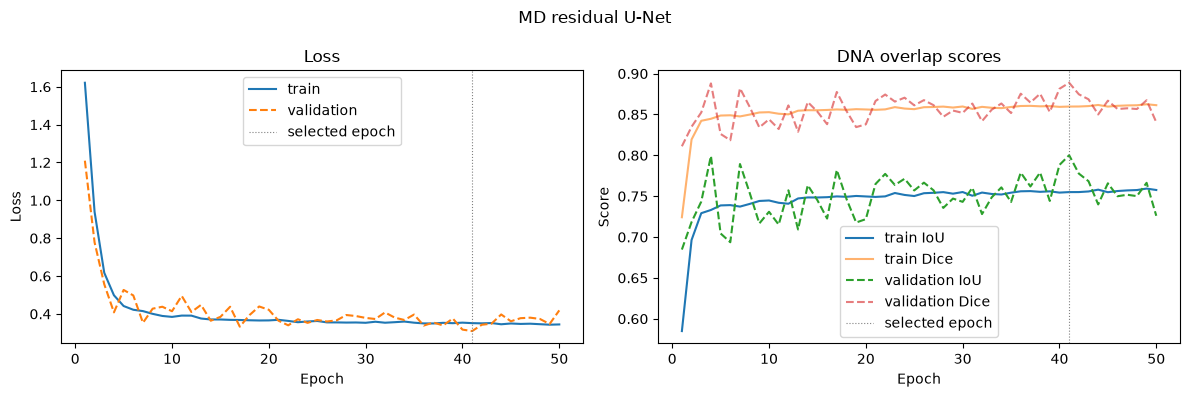

In [16]:
seg.plot_training_history(history, title=f"{'MD' if USE_MD else 'non-MD'} {ARCHITECTURE} U-Net")

## 14. DNA-focused validation metrics

The network is evaluated on the validation set of the dataset from section 10: the loss, DNA Dice and DNA IoU (threshold 0.5) and the mean squared error of the crossing map, averaged over all validation images (`seg.evaluate_loader`). For one batch, it then compares the crossing probability at crossings with that on ordinary DNA and on background. A good crossing head is high at crossings and low elsewhere.

For a loaded checkpoint this measures how well it generalises to your newly generated data. Small differences from its recorded validation scores are expected: the checkpoints were validated on TopoStats grain crops of their own datasets.

In [17]:
if val_loader is not None:
    val_metrics = seg.evaluate_loader(unet_app.model, val_loader, loss_fn, "validation")
    seg.inspect_crossing_batch(next(iter(val_loader)), unet_app.model)
else:
    print("No simulated dataset loaded (see section 10).")

validation {'loss': 0.2475, 'dna_dice': 0.8851, 'dna_iou': 0.7939, 'cross_mse': 0.0027}


Crossing target max: 1.0
Crossing prediction max: 0.991
Crossing pixels in batch: 2633 | DNA pixels: 6790
Mean prediction at crossings: 0.36
Mean prediction on non-crossing DNA: 0.006
Mean prediction on background: 0.044


### Prediction preview

For a few validation samples: the normalised input, the DNA target and prediction, and the crossing target and prediction (probabilities from 0 = black to 1 = white).

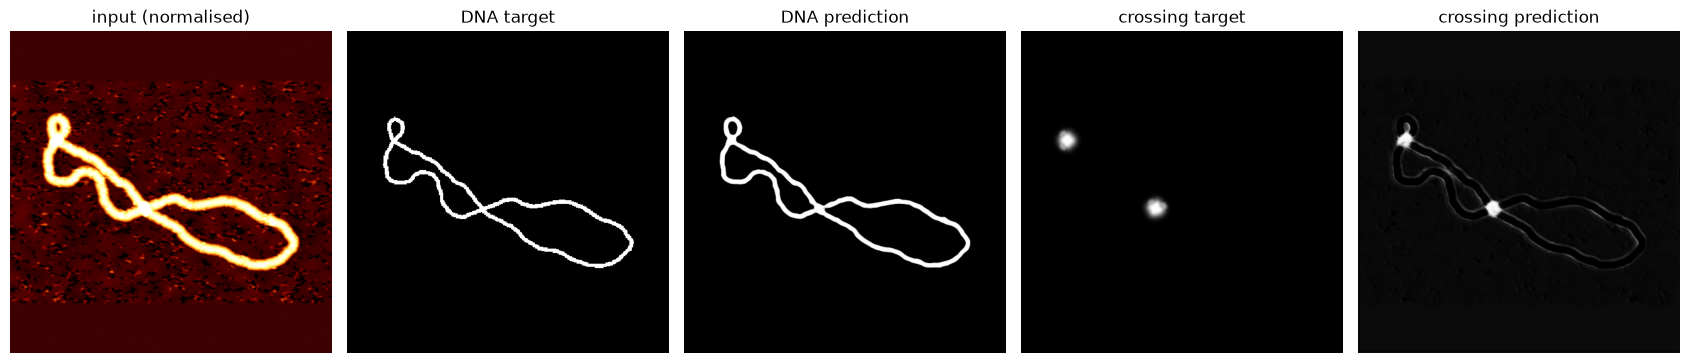

In [18]:
if val_loader is not None:
    preview_batch = next(iter(val_loader))
    for index in range(min(2, len(preview_batch[0]))):
        seg.show_prediction(preview_batch, unet_app.model, index=index)

## 15. Evaluation on real data

Now the network is applied to real AFM data. Choose **what** to analyse and **what type** of data it is:

| `REAL_INPUT` | `REAL_DATA_TYPE` | What happens |
|---|---|---|
| `"dataset"` | `"npy"` or `"image"` | Every image in `REAL_DATASET_DIR` is segmented. Images with a matching mask (`mask_<name>`) are cropped to the molecule (mask bounding box + `CROP_TO_MOLECULE_PADDING_PX`) like a TopoStats grain, segmented, and scored: Dice, IoU, precision, recall, and the predicted vs true DNA length (mask skeleton). A table, box plots and example overlays are shown. |
| `"single"` | `"npy"` or `"image"` | `REAL_SINGLE_FILE` is segmented as a whole, and the DNA mask, crossing map and a quick length estimate (mask skeleton) are shown. |
| `"single"` / `"dataset"` | `"spm"` | The raw AFM scan(s) are analysed with **TopoStats**, which uses this U-Net for segmentation (below). |

* `.npy` files must contain heights in nm, already flattened (like the test data in `../common-assets/real-test-data`).
* Image files (`.png`, `.jpg`, `.tif`) contain grey values, which are mapped linearly onto `IMAGE_HEIGHT_RANGE_NM`.
* Set `REAL_NM_PER_PIXEL` to convert lengths to nm (`.spm` files carry their own pixel size).

**TopoStats.** [TopoStats](https://github.com/AFM-SPM/TopoStats) is an open-source pipeline for AFM images of DNA. For each `.spm` scan it:

1. **filters** the raw scan: row alignment, tilt removal and flattening, so the substrate is at 0 nm;
2. **finds grains**: pixels above a height threshold (`grain_threshold_nm`) form candidate molecules, size-filtered by `grain_area_thresholds_nm2`, each cut out with a margin (`grain_crop_padding`). **The U-Net then re-segments every grain crop**, and pixels with DNA probability above `confidence` form the final mask;
3. **traces** each grain: skeletonises the mask, prunes short branches (`pruning_max_length_nm`), finds and resolves crossings (*nodestats*: `node_joining_length_nm`, `node_extend_dist_nm`), orders the trace(s) and fits splines. The result is the **contour length** of each molecule, whether it is circular, and the crossings in each grain.

**Choose the YAML source.** `TOPOSTATS_CONFIG_SOURCE = "preset"` is the default and uses your experiment's fine-tuned `relaxed`, `supercoiled` or `minicircle` YAML in `configs/`. The exposed settings below start from that preset and can be edited. **The preset files and their fine-tuned values have not been changed.**

Set `TOPOSTATS_CONFIG_SOURCE = "custom"` to use your own **full TopoStats 2.4.2 YAML**. Put its path in `TOPOSTATS_CUSTOM_YAML`; if the field is blank, the cell prompts for the path. All nested scientific settings in that file are used and validated. The flat `TOPOSTATS_SETTINGS` controls are for preset mode only. In both modes, the notebook sets the current input/output paths, selected U-Net checkpoint, one worker, and disables TopoStats plot saving because it draws its own figures.

Raw `.spm` analysis on Python 3.12 uses the **ASAP contour profile** installed by section 0 (`python setup_topostats.py` locally). The notebook's PyTorch U-Net is connected for the current session. Filtering, grain statistics, crossing resolution, ordered traces and splined contour lengths are computed.


In [19]:
REAL_INPUT = "single"          # "single" or "dataset"
REAL_DATA_TYPE = "spm"         # "spm", "npy" (heights in nm), or "image"
REAL_SINGLE_FILE = Path("../common-assets/example-spm/20240513_rel_PJIP37_unknot_4ng_eph_ni__.0_00090.spm")
REAL_DATASET_DIR = Path("../common-assets/real-test-data")
REAL_NM_PER_PIXEL = 0.5
DNA_THRESHOLD = 0.5
IMAGE_HEIGHT_RANGE_NM = (0.0, 4.0)
CROP_TO_MOLECULE_PADDING_PX = 40

# YAML source: experiment's fine-tuned settings by default, or your own full YAML.
TOPOSTATS_CONFIG_SOURCE = "preset"       # "preset" or "custom"
TOPOSTATS_PRESET = "relaxed"             # "relaxed", "supercoiled", "minicircle"
TOPOSTATS_CUSTOM_YAML = ""               # e.g. "/content/config.yaml"; prompted if custom and blank
TOPOSTATS_CHECKPOINT = TRAINED_CHECKPOINT or CHECKPOINT_PATH
TOPOSTATS_OUTPUT_DIR = Path("topostats_output")

if TOPOSTATS_CONFIG_SOURCE == "custom" and not str(TOPOSTATS_CUSTOM_YAML).strip():
    TOPOSTATS_CUSTOM_YAML = input("Path to your full TopoStats YAML file: ").strip()
TOPOSTATS_YAML = seg.select_topostats_yaml(
    TOPOSTATS_CONFIG_SOURCE, TOPOSTATS_PRESET, TOPOSTATS_CUSTOM_YAML)
TOPOSTATS_SETTINGS = {}
if TOPOSTATS_CONFIG_SOURCE == "preset":
    p = seg.exposed_topostats_settings(TOPOSTATS_YAML)
    TOPOSTATS_SETTINGS = dict(
        # U-Net settings (normalisation in nm, matching the checkpoint)
        confidence=p["confidence"],
        lower_norm_bound=p["lower_norm_bound"],
        upper_norm_bound=p["upper_norm_bound"],
        remove_disconnected_grains=p["remove_disconnected_grains"],
        # Common settings: edit these values to override the fine-tuned preset
        filter_threshold_method=p["filter_threshold_method"],
        filter_gaussian_size=p["filter_gaussian_size"],
        grain_threshold_nm=p["grain_threshold_nm"],
        grain_area_thresholds_nm2=p["grain_area_thresholds_nm2"],
        grain_crop_padding=p["grain_crop_padding"],
        remove_edge_intersecting_grains=p["remove_edge_intersecting_grains"],
        pruning_max_length_nm=p["pruning_max_length_nm"],
        node_joining_length_nm=p["node_joining_length_nm"],
        node_extend_dist_nm=p["node_extend_dist_nm"],
    )
print(f"YAML source: {TOPOSTATS_CONFIG_SOURCE} | {TOPOSTATS_YAML.resolve()}")
for name, value in TOPOSTATS_SETTINGS.items():
    print(f"{name:32s} {value}")


YAML source: preset | C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\segmentation\configs\topostats_relaxed.yaml
confidence                       0.3
lower_norm_bound                 -1.0
upper_norm_bound                 5.0
remove_disconnected_grains       True
filter_threshold_method          std_dev
filter_gaussian_size             1.1
grain_threshold_nm               [0.7]
grain_area_thresholds_nm2        [[2000, None]]
grain_crop_padding               10
remove_edge_intersecting_grains  True
pruning_max_length_nm            15.0
node_joining_length_nm           17.0
node_extend_dist_nm              20.0


### Segmentation results

The data chosen above is loaded and analysed:

* **single `.spm`**: TopoStats' filtered image, the grain mask from the U-Net, and the ordered traces (splines) labelled with grain number and contour length, followed by a table of every molecule (contour length, circular or linear, crossings in its grain);
* **dataset** (`.npy` / images with masks): summary statistics, per-image scores, predicted vs true DNA length, and example overlays (prediction in colour, true mask outlined in red);
* **single `.npy` / image**: the image, the DNA mask with a length estimate, and the crossing map.

The predictor class connects a checkpoint to TopoStats: TopoStats creates it from the checkpoint path and asks it for the DNA probability of each grain crop.

ASAP contour profile: Jones-polynomial knot/link classification is omitted. Contour length, circularity and crossing counts are computed normally.


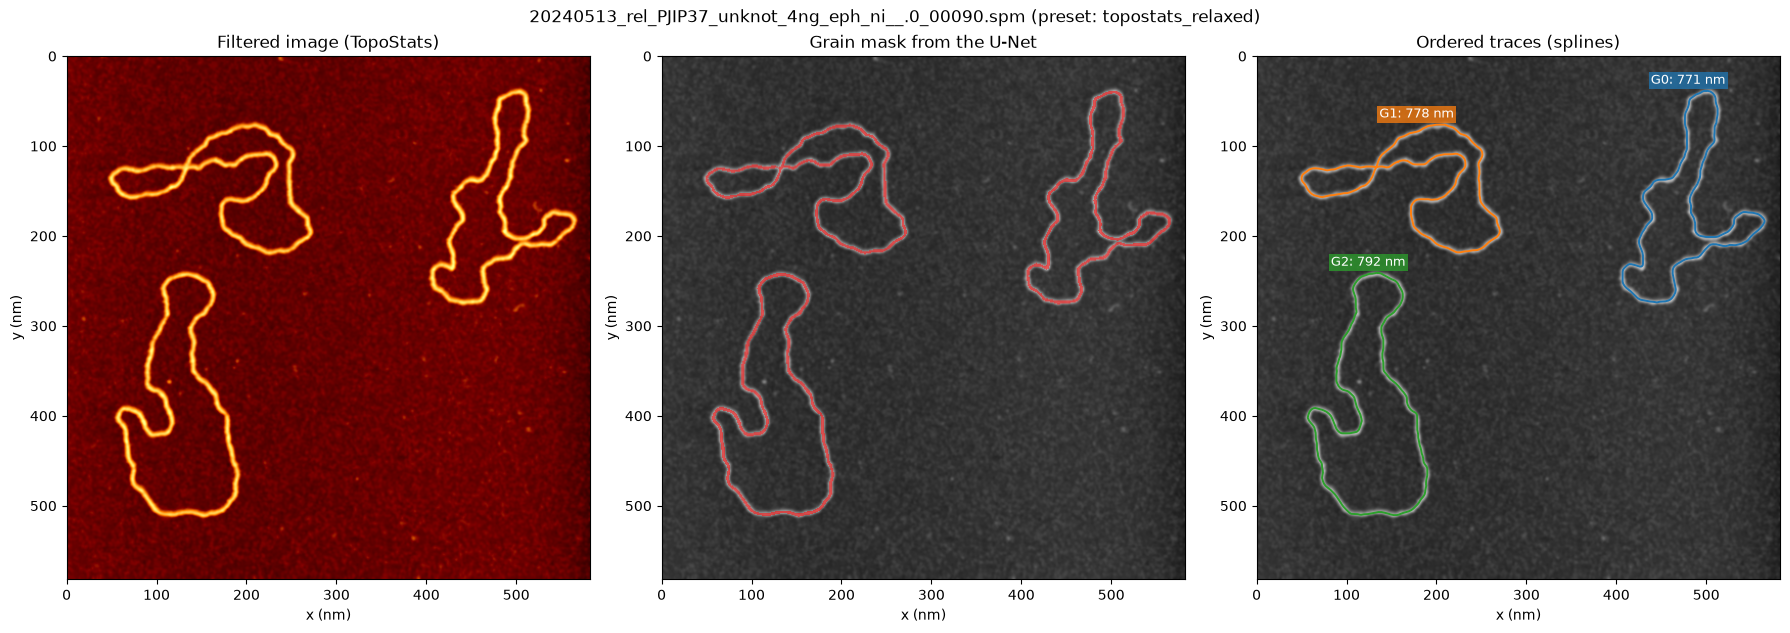

,grain,molecule,contour_length_nm,circular,crossings_in_grain
0,0,0,771.0,True,0
1,1,0,778.2,True,1
2,2,0,791.8,True,0


In [20]:
class TorchUNetPredictor:
    """A checkpoint of this notebook, packaged as TopoStats' U-Net.

    TopoStats creates the predictor from the `model_path` in its
    configuration. The network (simple U-Net or Res-U-Net) is built from
    the checkpoint's metadata and its weights are loaded.
    `native_probability()` preprocesses one grain crop exactly as during
    training and returns the DNA probability at the crop's own pixels.

    Parameters
    ----------
    model_path: str | Path
        Checkpoint saved by this notebook (``checkpoints/*.pt``).
    input_size: int | None, optional
        Network input size in pixels. Defaults to `None`, which uses the
        size stored in the checkpoint (or ``TARGET_SIZE``).
    device: str | None, optional
        Device for the network. Defaults to `None`, which uses the GPU if
        one is available.

    Attributes
    ----------
    metadata: dict[str, Any]
        The checkpoint's metadata.
    model: nn.Module
        The network, in evaluation mode.
    input_shape: tuple[int | None, int, int, int]
        ``(None, size, size, 1)``, the Keras-style shape TopoStats reads.
    output_shape: tuple[int | None, int, int, int]
        Same as ``input_shape``.

    Methods
    -------
    `native_probability(image, ...) -> np.ndarray`
        DNA probability of one grain crop at its own pixels.

    Examples
    --------
    >>> predictor = TorchUNetPredictor(
    ...     "checkpoints/md_simple_unet.pt", device="cpu"
    ... )
    >>> predictor.input_shape
    (None, 512, 512, 1)
    >>> crop = np.zeros((90, 120), dtype=np.float32)
    >>> predictor.native_probability(crop).shape
    (90, 120)

    """

    metadata: dict[str, Any]
    model: nn.Module
    input_shape: tuple[int | None, int, int, int]
    output_shape: tuple[int | None, int, int, int]

    def __init__(
        self: TorchUNetPredictor,
        model_path: str | Path,
        input_size: int | None = None,
        device: str | None = None,
    ) -> None:
        """Build the network from a checkpoint and load its weights.

        Parameters
        ----------
        model_path: str | Path
            Checkpoint saved by this notebook.
        input_size: int | None, optional
            Network input size in pixels. Defaults to `None` (from the
            checkpoint).
        device: str | None, optional
            Device for the network. Defaults to `None` (GPU if
            available).

        """

        payload = torch.load(
            model_path, map_location="cpu", weights_only=True
        )
        self.metadata = (
            payload.get("metadata", {}) if isinstance(payload, dict) else {}
        )
        architecture = str(self.metadata.get("architecture", ""))
        if architecture.startswith("SimpleUNet"):
            self.model = SimpleUNet()
        else:
            model_config = self.metadata.get("model_config", MODEL_CFG)
            self.model = ResUNetTwoHeads(**model_config)
        device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        seg.load_checkpoint(self.model, model_path, device)
        size = int(input_size or self.metadata.get("input_size", TARGET_SIZE))
        self.input_shape = (None, size, size, 1)
        self.output_shape = (None, size, size, 1)

    def native_probability(
        self: TorchUNetPredictor,
        image: np.ndarray,
        lower_norm_bound: float = -1.0,
        upper_norm_bound: float = 5.0,
    ) -> np.ndarray:
        """DNA probability of one grain crop at its own pixels.

        The crop is normalised, resized and padded as during training
        (`seg.prepare_height`), passed through the network, and the
        probability is restored to the crop's shape.

        Parameters
        ----------
        image: np.ndarray
            Grain crop (heights in nm).
        lower_norm_bound: float, optional
            Height mapped to 0 in nm. Defaults to -1.0.
        upper_norm_bound: float, optional
            Height mapped to 1 in nm. Defaults to 5.0.

        Returns
        -------
        np.ndarray
            DNA probability with the shape of ``image``.

        Examples
        --------
        >>> predictor = TorchUNetPredictor(
        ...     "checkpoints/md_simple_unet.pt", device="cpu"
        ... )
        >>> crop = np.zeros((90, 120), dtype=np.float32)
        >>> probability = predictor.native_probability(crop)
        >>> bool(probability.min() >= 0 and probability.max() <= 1)
        True

        """

        dna_prob, _ = seg.predict_native(
            self.model,
            np.asarray(image, dtype=np.float32),
            (lower_norm_bound, upper_norm_bound),
            self.input_shape[1],
        )
        return dna_prob


real_input_path = (REAL_SINGLE_FILE if REAL_INPUT == "single" else REAL_DATASET_DIR).resolve()
if not real_input_path.exists():
    print(f"{real_input_path} was not found. The real data in ../common-assets/ is only available in a "
          "copy of the repository (not on Colab or Kaggle); set REAL_SINGLE_FILE or REAL_DATASET_DIR "
          "to your own data.")
elif REAL_DATA_TYPE == "spm":
    seg.install_topostats_unet_patch(TorchUNetPredictor)
    spm_files = [REAL_SINGLE_FILE] if REAL_INPUT == "single" else sorted(REAL_DATASET_DIR.glob("*.spm"))
    all_molecules = []
    for spm_file in spm_files:
        topostats_config = seg.build_topostats_config(
            TOPOSTATS_YAML, TOPOSTATS_SETTINGS, spm_file,
            TOPOSTATS_CHECKPOINT, TOPOSTATS_OUTPUT_DIR)
        topostats_result = seg.run_topostats(spm_file, topostats_config)
        table = seg.show_topostats_results(topostats_result, title=f"{spm_file.name} ({TOPOSTATS_CONFIG_SOURCE}: {TOPOSTATS_YAML.stem})")
        all_molecules.append(table.assign(file=spm_file.name))
    molecules = pd.concat(all_molecules, ignore_index=True) if all_molecules else pd.DataFrame()
elif REAL_INPUT == "dataset":
    pairs = seg.collect_real_pairs(REAL_DATASET_DIR, REAL_DATA_TYPE)
    print(f"Found {len(pairs)} images ({sum(p['mask_path'] is not None for p in pairs)} with masks) in {REAL_DATASET_DIR}")
    real_results = seg.evaluate_real_dataset(
        unet_app.model, pairs, REAL_DATA_TYPE, DNA_THRESHOLD, REAL_NM_PER_PIXEL,
        CROP_TO_MOLECULE_PADDING_PX, IMAGE_HEIGHT_RANGE_NM)
    seg.show_real_dataset_results(
        real_results, unet_app.model, pairs, REAL_DATA_TYPE, DNA_THRESHOLD,
        CROP_TO_MOLECULE_PADDING_PX, length_unit="nm" if REAL_NM_PER_PIXEL else "px",
        image_height_range_nm=IMAGE_HEIGHT_RANGE_NM)
else:
    single_result = seg.analyse_single_image(
        unet_app.model, REAL_SINGLE_FILE, REAL_DATA_TYPE, DNA_THRESHOLD, REAL_NM_PER_PIXEL,
        IMAGE_HEIGHT_RANGE_NM)
    seg.show_single_image_result(single_result)

## Further resources

For more advanced analysis of biomolecules, including identification of knots using polynomial invariants, catenanes and linking, visit [TopoStats](https://github.com/AFM-SPM/TopoStats).

For other simulated microscopy workflows and implementations of deep learning in microscopy, visit [DeepTrackAI](https://github.com/DeepTrackAI).

## Cite ASAP

[Prakhar Dutta](https://www.spiedigitallibrary.org/profile/notfound?author=Prakhar_Dutta), [Jiacheng Huang](https://www.spiedigitallibrary.org/profile/notfound?author=Jiacheng_Huang), [Nazli Demirpehlivan](https://www.spiedigitallibrary.org/profile/notfound?author=Nazli_Demirpehlivan), et al. "ASAP (AFM simulation and analysis pipeline): a unified deep learning framework for simulation, quality control, and segmentation in atomic force microscopy", Proc. SPIE 14198, Emerging Topics in Artificial Intelligence (ETAI) 2026, 1419804 (9 Oct 2026); [https://doi.org/10.1117/12.3113626](https://doi.org/10.1117/12.3113626)
